# Preparación y limpieza de datos con un proceso ETL
## Análisis del rendimiento de los cultivos del Valle del Cauca y su relación con la temperatura

**Asignatura:** Ciencia de Datos con Python (IGS38) · Universidad Santiago de Cali

**Caso de estudio:** Analítica de datos abiertos de Colombia con datos.gov.co

**Parte 1:** Identificación de fuentes de datos y manipulación con Pandas (RA1 y RA2)

**Autor:** Juan David Muñoz Sotelo

Este proyecto lleva **siete conjuntos de datos abiertos** de datos agrícolas del Valle del Cauca. Desde los CSV tal como los entrega el portal hasta tablas **limpias, validadas y documentadas**

## Pregunta
¿Cómo ha evolucionado el rendimiento de los principales cultivos del Valle del Cauca a lo largo del tiempo y qué relación existe entre sus variaciones y la temperatura registrada en los municipios donde se producen?

## Hipótesis
El aumento de la temperatura se asocia con una disminución del rendimiento agrícola, expresado en toneladas por hectárea, en los principales cultivos del Valle del Cauca. Esta asociación podría ser más pronunciada en los cultivos transitorios que en los permanentes, debido a sus diferencias en los ciclos productivos y en la exposición a las condiciones climáticas.

## ¿Por qué estos datos están "sucios"?

Los datos abiertos reales casi nunca llegan listos para analizar. En este caso aparecen los problemas típicos:

- **Fuentes distintas, formatos distintos.** Cada CSV escribe los números a su manera: `1,6` (coma decimal), `2.124,4` (punto de miles y coma decimal) o `4,324.8` (coma de miles y punto decimal). Una conversión directa con `to_numeric` los convertiría en `NaN` o, peor, en un número equivocado.
- **Códigos que parecen números.** El código DIVIPOLA `76001` aparece como `76,001` y el año como `2,000`. Si se lee como número se pierden ceros y separadores se vuelven parte del valor.
- **Nombres y códigos inconsistentes.** Columnas que se llaman distinto en cada conjunto (`ano`, `rendimiento_toneladas_hectareas`...), tildes usadas de forma irregular (`Bolivar` y `El Aguila` sin tilde, `La Unión` con tilde) y códigos de cultivo a los que el portal les quitó los ceros finales (`20436` en lugar de `2043600`).
- **Llaves repetidas.** El mismo año–municipio–cultivo–ciclo aparece varias veces, a veces como copia exacta y a veces con valores distintos.
- **Ceros y valores imposibles.** Rendimientos de 0 donde no hubo siembra y errores de digitación (cacao con 45 t/ha, repollo con 240).
- **Variables que faltan.** El consolidado de permanentes no trae `subregion`.

Limpiar no es "arreglar a ojo": cada decisión debe estar **justificada**, **verificada** y **documentada**.

## ETL y ELT

Organizamos el trabajo como un proceso **ETL** (*Extract, Transform, Load*):

| Etapa | Qué hacemos en este cuaderno |
|---|---|
| **E — Extraer** | Leer los CSV descargados del portal, todos como texto. |
| **T — Transformar** | Explorar, eliminar lo que sobra, corregir errores, estructurar, asignar tipos, unir tablas y completar faltantes. |
| **L — Cargar** | Guardar los conjuntos limpios en CSV listos para el análisis. |

### ¿En qué se diferencia de ELT?

En **ETL** los datos se transforman **antes** de guardarlos en el destino: al final solo quedan datos limpios. En **ELT** (*Extract, Load, Transform*) se **carga primero** el dato en bruto en un almacén o *data lake* y se transforma después, dentro de ese sistema.

| | ETL | ELT |
|---|---|---|
| Orden | Extraer → Transformar → Cargar | Extraer → Cargar → Transformar |
| Dónde se transforma | En un proceso intermedio (aquí, `pandas`) | Dentro del destino (almacén o *data lake*) |
| Qué se guarda | Solo datos limpios | Datos en bruto + transformaciones |
| Uso típico | Volumen moderado, esquema conocido | Grandes volúmenes, datos no estructurados |

**En este caso:** los siete conjuntos de datos agrícolas contienen entre 1.700 y 17.000 filas aproximadamente, por lo que un proceso ETL en memoria con `pandas` es suficiente para su limpieza y transformación.
## Ruta

1. **Extraer**: lectura de los 7 CSV.
2. **Transformar**
   - Armonización de nombres y exploración inicial (diagnóstico).
   - T1. Eliminar lo que no sirve (copias exactas, columnas vacías).
   - T2. Corregir los datos incorrectos (espacios, marcadores, códigos, nombres).
   - T3. Estructurar (tipos, rangos, reglas de consistencia, llaves, *merge*, ceros, atípicos, índice de rendimiento y producción).
   - T4. Completar (qué faltantes se imputan y cuáles no).
3. **Cargar**: guardar los conjuntos limpios.
4. **Validación final** sobre los archivos guardados.
5. **Reporte de calidad**, resumen de cambios, decisiones y conclusiones.

## Fuentes de datos

Todos los conjuntos se descargaron de [datos.gov.co](https://www.datos.gov.co) el **23 de octubre de 2026** en formato CSV (descarga manual desde el portal, según lo indicado por el docente para este primer laboratorio) y se guardaron en `data/datos_gov_co`.

| Conjunto | ID | Archivo | Rol en el análisis | Enlace |
|---|---|---|---|---|
| Rendimiento del área cosechada, transitorios | `xb5v-aufn` | `rend_trans.csv` | **Conjunto principal.** Variable objetivo (t/ha) | [Ver](https://www.datos.gov.co/Agricultura-y-Desarrollo-Rural/Rendimiento-del-rea-cosechada-de-los-cultivos-tran/xb5v-aufn/data_preview) |
| Superficie sembrada, transitorios | `vs5v-e66i` | `sup_trans.csv` | Hectáreas (ponderación) | [Ver](https://www.datos.gov.co/Agricultura-y-Desarrollo-Rural/Superficie-sembrada-de-cultivos-transitorios-en-el/vs5v-e66i/data_preview) |
| Superficie sembrada, permanentes | `v4ub-9eme` | `sup_perm.csv` | Hectáreas, catálogo de subregiones y validación cruzada | [Ver](https://www.datos.gov.co/Agricultura-y-Desarrollo-Rural/Superficie-sembrada-de-cultivos-permanentes-en-el-/v4ub-9eme/data_preview) |
| Consolidado agrícola, permanentes | `exfh-span` | `consol_perm.csv` | Producción y rendimiento (permanentes) | [Ver](https://www.datos.gov.co/Agricultura-y-Desarrollo-Rural/Consolidado-agr-cola-por-municipios-de-los-cultivo/exfh-span/data_preview) |
| Producción de raíces, tubérculos y bulbos | `5m3h-gjmu` | `raices.csv` | Producción (toneladas) | [Ver](https://www.datos.gov.co/Agricultura-y-Desarrollo-Rural/Producci-n-de-ra-ces-tub-rculos-y-bulbos-en-el-Val/5m3h-gjmu/data_preview) |
| Producción de hortalizas | `6bym-ygip` | `hortalizas.csv` | Producción (toneladas) | [Ver](https://www.datos.gov.co/Agricultura-y-Desarrollo-Rural/Producci-n-de-hortalizas-en-el-Valle-del-Cauca/6bym-ygip/data_preview) |
| Producción de frutales | `8xap-gecf` | `frutales.csv` | Producción (toneladas) | [Ver](https://www.datos.gov.co/Agricultura-y-Desarrollo-Rural/Producci-n-de-frutales-en-el-Valle-del-Cauca/8xap-gecf/data_preview)

### Ficha de documentación de cada conjunto (RA1)

La *fecha de corte* es la que informa el portal en la ficha de cada conjunto; la *fecha de descarga* de los archivos es el 23 de octubre de 2026.

| ID | Entidad | Fecha de corte | Frecuencia de actualización | Licencia |
|---|---|---|---|---|
| `xb5v-aufn` | Gobernación del Valle del Cauca | 18 de mayo de 2026 | No informada en la ficha del portal | CC BY-SA |
| `vs5v-e66i` | Gobernación del Valle del Cauca | 18 de mayo de 2026 | No informada en la ficha del portal | CC BY-SA |
| `v4ub-9eme` | Gobernación del Valle del Cauca | 18 de mayo de 2026 | No informada en la ficha del portal | CC BY-SA |
| `exfh-span` | Gobernación del Valle del Cauca | 16 de septiembre de 2026 | No informada en la ficha del portal | CC BY-SA |
| `5m3h-gjmu` | Gobernación del Valle del Cauca | 18 de mayo de 2026 | No informada en la ficha del portal | CC BY-SA |
| `6bym-ygip` | Gobernación del Valle del Cauca | 18 de mayo de 2026 | No informada en la ficha del portal | CC BY-SA |
| `8xap-gecf` | Gobernación del Valle del Cauca | 18 de mayo de 2026 | No informada en la ficha del portal | CC BY-SA |

*CC BY-SA = Creative Commons Atribución-CompartirIgual.*

### Diccionario de datos

| Columna | Descripción | Tipo final | Unidad |
|---|---|---|---|
| `anio` | Año del registro | `int` | año |
| `id_municipio` | Código **DIVIPOLA** del municipio (5 dígitos, el Valle del Cauca empieza en `76`) | `str` | — |
| `municipio` | Nombre del municipio | `str` | — |
| `subregion` | Subregión del Valle (Centro, Norte, Pacífico, Sur) | `str` | — |
| `id_cultivo`, `cultivo` | Código del cultivo (7 dígitos; los maíces tienen 8) y nombre | `str` | — |
| `ciclo` | Semestre 1, Semestre 2 (transitorios) o Anual (permanentes) | `str` | — |
| `rendimiento_t_ha` | Rendimiento del área cosechada | `float` | toneladas / hectárea |
| `hectareas_sembradas`, `hectareas_cosechadas` | Superficie | `float` | hectáreas |
| `produccion_toneladas` | Producción | `float` | toneladas |
| `tipo_cultivo` | Clasificación del consolidado (frutales, hortalizas, flores...) | `str` | — |
| `grupo` | *Columna creada.* `Transitorio` o `Permanente` según el conjunto de origen | `str` | — |
| `es_cero`, `sin_siembra` | *Columnas creadas.* Rendimiento 0 / rendimiento 0 con 0 hectáreas | `bool` | — |
| `mediana_cultivo`, `atipico` | *Columnas creadas.* Mediana del rendimiento del cultivo y marca de atípico (> 5 × mediana) | `float`, `bool` | t/ha |
| `alerta_consistencia` | *Columna creada.* Marca de registros que violan una regla de consistencia | `bool` | — |

### Verificación de librerías
Antes de ejecutar el notebook comprobar que las librerías necesarias estén instaladas en el `requirements.txt` estan las requeridas. Después de instalar.

In [144]:
import sys
import subprocess
import importlib

# nombre para importar -> nombre del paquete en pip
LIBRERIAS = {
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "seaborn": "seaborn",
    "scipy": "scipy",
    "requests": "requests",
    "IPython": "ipython"
}

print(f"Python del kernel: {sys.executable}\n")
instaladas_ahora, fallidas = [], []

for modulo, paquete in LIBRERIAS.items():
    try:
        m = importlib.import_module(modulo)
        print(f"{modulo:<12} ya estaba instalada (versión {getattr(m, '__version__', '?')})")
    except ImportError:
        print(f"{modulo:<12} no está instalada, instalando...")
        resultado = subprocess.run([sys.executable, "-m", "pip", "install", paquete],
                                   capture_output=True, text=True)
        if resultado.returncode == 0:
            print(f"{modulo:<12} instalada correctamente")
            instaladas_ahora.append(modulo)
        else:
            print(f"{modulo:<12} falló la instalación:")
            print(resultado.stderr[-400:])
            fallidas.append(modulo)

print()
if fallidas:
    print("No se pudo instalar:", ", ".join(fallidas), "· revisa tu conexión a internet o tus permisos.")
elif instaladas_ahora:
    print("Se instalaron:", ", ".join(instaladas_ahora))
    print("IMPORTANTE: reinicia el kernel (Kernel > Restart) y ejecuta el notebook desde la primera celda.")
else:
    print("Todo estaba instalado. Puedes ejecutar el notebook.")

Python del kernel: c:\Users\juand\Downloads\Ciencia de datos\.venv\Scripts\python.exe

numpy        ya estaba instalada (versión 2.5.4)
pandas       ya estaba instalada (versión 3.1.1)
matplotlib   ya estaba instalada (versión 3.11.2)
seaborn      ya estaba instalada (versión 0.13.2)
scipy        ya estaba instalada (versión 1.18.1)
requests     ya estaba instalada (versión 2.34.2)
IPython      ya estaba instalada (versión 9.18.1)

Todo estaba instalado. Puedes ejecutar el notebook.


## Constantes y configuración

Se definen una sola vez las rutas, la llave de cruce, el **formato numérico de cada archivo** y los **parámetros de limpieza**. Si se requiere cambiar una regla (por ejemplo, el factor de atípicos o el rango de temperatura plausible), solo se toca aquí y hacemos mas mantenible el codigo.

In [145]:
import os
import re
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 80)

FECHA_DESCARGA = "2026-10-23"
CARPETA_SALIDA = "data/procesados"
ARCHIVO_SALIDA = f"{CARPETA_SALIDA}/cultivos_limpio.csv"
os.makedirs(CARPETA_SALIDA, exist_ok=True)

RUTAS = {
    "raices":      "data/datos_gov_co/raices.csv",
    "rend_trans":  "data/datos_gov_co/rend_trans.csv",
    "sup_trans":   "data/datos_gov_co/sup_trans.csv",
    "sup_perm":    "data/datos_gov_co/sup_perm.csv",
    "consol_perm": "data/datos_gov_co/consol_perm.csv",
    "hortalizas":  "data/datos_gov_co/hortalizas.csv",
    "frutales":    "data/datos_gov_co/frutales.csv",
}
NOMBRES_AGRO = list(RUTAS)
FUENTES_PROD = ["raices", "hortalizas", "frutales"]

# Formato numérico de cada CSV (se comprueba en la exploración):
#   "es": 2.124,4 = 2124.4   |   "en": 4,324.8 = 4324.8
FORMATO_NUM = {"raices": "es", "rend_trans": "es", "sup_trans": "es", "sup_perm": "es",
               "hortalizas": "es", "frutales": "es", "consol_perm": "en"}
COLS_NUM = {
    "raices":      ["produccion_toneladas"],
    "rend_trans":  ["rendimiento_t_ha"],
    "sup_trans":   ["hectareas_sembradas"],
    "sup_perm":    ["hectareas_sembradas"],
    "consol_perm": ["hectareas_sembradas", "hectareas_cosechadas", "produccion_toneladas", "rendimiento_t_ha"],
    "hortalizas":  ["produccion_toneladas"],
    "frutales":    ["produccion_toneladas"],
}

LLAVE = ["anio", "id_municipio", "id_cultivo", "ciclo"]
BASE_COLS = ["anio", "id_municipio", "municipio", "id_cultivo", "cultivo", "ciclo"]
REQUERIDAS = {
    "raices":      BASE_COLS + ["subregion", "produccion_toneladas"],
    "hortalizas":  BASE_COLS + ["subregion", "produccion_toneladas"],
    "frutales":    BASE_COLS + ["subregion", "produccion_toneladas"],
    "rend_trans":  BASE_COLS + ["subregion", "rendimiento_t_ha"],
    "sup_trans":   BASE_COLS + ["subregion", "hectareas_sembradas"],
    "sup_perm":    BASE_COLS + ["subregion", "hectareas_sembradas"],
    "consol_perm": BASE_COLS + ["tipo_cultivo", "hectareas_sembradas", "hectareas_cosechadas",
                                "produccion_toneladas", "rendimiento_t_ha"],
}
SUBREGIONES = {"Centro", "Norte", "Pacifico", "Sur"}

# Parámetros de limpieza
ANIO_MIN, ANIO_MAX = 2000, 2023
FACTOR_ATIPICO = 5            # rendimiento > 5 x mediana de su cultivo = atípico
TOL_PRODUCCION = 0.05         # tolerancia (5 %) producción ≈ rendimiento x cosechadas
LARGO_ID_CULTIVO = 7
CORREGIR_ID_CULTIVO = True    # rellenar con ceros finales los códigos truncados
MARCADORES_FALTANTE = {"", "SIN DATO", "S/D", "N/A", "NA", "NULL", "NONE", "-", "SIN INFORMACION", "NO REPORTA"}

# Bitácoras para el reporte de calidad
LOG_ETAPAS, LOG_CONVERSION, CAMBIOS = [], [], []
print("Listo · pandas", pd.__version__)

Listo · pandas 3.1.1


## Funciones auxiliares
- `normalizar_columnas`: encabezados en minúsculas, sin tildes ni espacios.
- `leer_csv`: lee todo **como texto** (`dtype=str`).
- `es_miles` / `a_numero`: convierten texto a número según el formato de cada archivo.
- `limpiar_codigo`: quita comas, puntos y espacios de un código y lo rellena con ceros a la izquierda si se pide.
- `quitar_tildes`: elimina tildes **conservando la Ñ**.
- `registrar` / `anotar`: bitácoras para el reporte final.

In [146]:
def normalizar_columnas(df):
    def limpiar(c):
        c = unicodedata.normalize("NFKD", str(c)).encode("ascii", "ignore").decode()
        return re.sub(r"[^0-9a-z]+", "_", c.strip().lower()).strip("_")
    df = df.copy()
    df.columns = [limpiar(c) for c in df.columns]
    return df

def leer_csv(nombre):
    ruta = RUTAS[nombre]
    if not os.path.exists(ruta):
        raise FileNotFoundError(f"Falta {ruta}: descárgalo del portal y guárdalo en data/")
    return normalizar_columnas(pd.read_csv(ruta, dtype=str))

def es_miles(s):
    return s.str.fullmatch(r"-?\d{1,3}(\.\d{3})+(,\d+)?").fillna(False).astype(bool)

def a_numero(serie, formato="es"):
    s = serie.str.replace(r"\s+", "", regex=True)
    if formato == "en":
        s = s.str.replace(",", "", regex=False)
    else:
        con_miles = es_miles(s)
        s = s.mask(con_miles, s.str.replace(".", "", regex=False))
        s = s.str.replace(",", ".", regex=False)
    return pd.to_numeric(s, errors="coerce")

def limpiar_codigo(s, largo=None):
    s = s.str.replace(r"[,.\s]", "", regex=True)
    return s.str.zfill(largo) if largo else s

def quitar_tildes(texto):
    if pd.isna(texto):
        return texto
    nfd = unicodedata.normalize("NFD", str(texto))
    salida = []
    for i, ch in enumerate(nfd):
        if unicodedata.combining(ch):
            if ch == "\u0303" and i > 0 and nfd[i - 1] in "Nn":
                salida.append(ch)
            continue
        salida.append(ch)
    return unicodedata.normalize("NFC", "".join(salida))

def n_distintos(antes, despues):
    ambos_nulos = antes.isna() & despues.isna()
    return int(((antes != despues) & ~ambos_nulos).sum())

def convertir(df, cols, nombre, formato):
    for c in cols:
        crudo = df[c]
        num = a_numero(crudo, formato)
        LOG_CONVERSION.append({"conjunto": nombre, "columna": c, "formato": formato,
                               "valores_con_dato": int(crudo.notna().sum()),
                               "no_convertidos": int((crudo.notna() & num.isna()).sum()),
                               "con_punto_de_miles": int(es_miles(crudo).sum()) if formato == "es" else 0})
        df[c] = num

def moda(s):
    m = s.mode()
    return m.iloc[0] if len(m) else pd.NA

def registrar(etapa, antes, despues, decision):
    LOG_ETAPAS.append({"etapa": etapa, "filas_antes": int(antes), "filas_despues": int(despues), "decision": decision})

def anotar(etapa, operacion, tipo, cantidad, detalle=""):
    CAMBIOS.append({"etapa": etapa, "operacion": operacion, "tipo": tipo, "cantidad": int(cantidad), "detalle": detalle})
print("Funciones listas")

Funciones listas


---
# 1. EXTRAER: lectura de los CSV

Todo se lee **como texto**: así no se pierden los ceros de los códigos (`76001`) ni se malinterpretan números como `1,6` o `2.124,4`. Los tipos se asignan después, de forma controlada. Se muestran forma, columnas y los primeros registros de cada conjunto.

In [147]:
crudos = {n: leer_csv(n) for n in NOMBRES_AGRO}
for n, d in crudos.items():
    display(d.head(10))

,ano,id_municipio,municipio,subregion,id_cultivo,cultivo,ciclo,produccion_toneladas
0,2000,76111,Buga,Centro,1050400,Ajo,Semestre 1,7
1,2000,76275,Florida,Sur,1080200,Arracacha,Anual,108
2,2000,76111,Buga,Centro,1080200,Arracacha,Anual,200
3,2000,76622,Roldanillo,Norte,1080200,Arracacha,Anual,617
4,2000,76828,Trujillo,Centro,1080200,Arracacha,Anual,240
5,2000,76246,El Cairo,Norte,1080200,Arracacha,Anual,7
6,2000,76892,Yumbo,Sur,1080200,Arracacha,Anual,133
7,2000,76834,Tuluá,Centro,1080200,Arracacha,Anual,48
8,2000,76863,Versalles,Norte,1080200,Arracacha,Anual,165
9,2000,76250,El Dovio,Norte,1080200,Arracacha,Anual,180


,ano,id_municipio,municipio,subregion,id_cultivo,cultivo,ciclo,rendimiento_toneladas_hectareas
0,2000,76111,Buga,Centro,1051100,Cebolla Bulbo,Semestre 1,7
1,2000,76111,Buga,Centro,1060201,Fríjol Plana,Semestre 1,"1,6"
2,2006,76111,Buga,Centro,1051100,Cebolla Bulbo,Semestre 1,10
3,2007,76111,Buga,Centro,1060500,Haba,Semestre 1,"1,5"
4,2008,76111,Buga,Centro,1051100,Cebolla Bulbo,Semestre 1,9
5,2010,76111,Buga,Centro,1053000,Zanahoria,Semestre 1,13
6,2000,76318,Guacarí,Centro,1051100,Cebolla Bulbo,Semestre 1,10
7,2001,76318,Guacarí,Centro,1051100,Cebolla Bulbo,Semestre 1,10
8,2006,76318,Guacarí,Centro,1051900,Lechuga,Semestre 1,14
9,2006,76001,Cali,Sur,1022100,Perejil,Semestre 1,3


,ano,id_municipio,municipio,subregion,id_cultivo,cultivo,ciclo,hectareas_sembradas
0,2000,76111,Buga,Centro,1051100,Cebolla Bulbo,Semestre 1,5
1,2000,76111,Buga,Centro,1060201,Fríjol Plana,Semestre 1,5
2,2006,76111,Buga,Centro,1051100,Cebolla Bulbo,Semestre 1,5
3,2007,76111,Buga,Centro,1060500,Haba,Semestre 1,5
4,2008,76111,Buga,Centro,1051100,Cebolla Bulbo,Semestre 1,5
5,2010,76111,Buga,Centro,1053000,Zanahoria,Semestre 1,5
6,2000,76318,Guacarí,Centro,1051100,Cebolla Bulbo,Semestre 1,5
7,2001,76318,Guacarí,Centro,1051100,Cebolla Bulbo,Semestre 1,5
8,2006,76318,Guacarí,Centro,1051900,Lechuga,Semestre 1,5
9,2006,76001,Cali,Sur,1022100,Perejil,Semestre 1,5


,ano,id_municipio,municipio,subregion,id_cultivo,cultivo,ciclo,hectareas_sembradas
0,2022,76233,Dagua,Sur,2045801,Plátano,Anual,1.264
1,2022,76100,Bolivar,Norte,2045801,Plátano,Anual,514
2,2022,76243,El Aguila,Norte,2045801,Plátano,Anual,2.100
3,2022,76001,Cali,Sur,2045801,Plátano,Anual,31
4,2022,76275,Florida,Sur,2045801,Plátano,Anual,"293,65"
5,2022,76400,La Unión,Norte,2045801,Plátano,Anual,"41,6"
6,2022,76306,Ginebra,Sur,2045801,Plátano,Anual,74
7,2022,76020,Alcalá,Norte,2045801,Plátano,Anual,1.200
8,2022,76250,El Dovio,Norte,2045801,Plátano,Anual,"200,7"
9,2022,76403,La Victoria,Norte,2045801,Plátano,Anual,98


,tipo_cultivo,ano,id_municipio,municipio,id_cultivo,cultivo,ciclo,hectareas_sembradas,hectareas_cosechadas,produccion_toneladas,rendimiento_toneladas_hectareas
0,Frutales,"2,000","76,001",Cali,"2,040,202",Aguacate,Anual,10,8,48,6
1,Frutales,"2,000","76,001",Cali,"20,436",Cítricos,Anual,75,10,150,15
2,Frutales,"2,000","76,001",Cali,"2,043,000",Guayaba,Anual,63,43,473,11
3,Frutales,"2,000","76,001",Cali,"2,043,700",Lulo,Anual,10,9,54,6
4,Frutales,"2,000","76,001",Cali,"2,044,700",Mora,Anual,10,8,48,6
5,Frutales,"2,000","76,001",Cali,"2,046,300",Tomate de Árbol,Anual,6,4,28,7
6,Frutales,"2,000","76,020",Alcalá,"2,040,202",Aguacate,Anual,10,10,60,6
7,Frutales,"2,000","76,020",Alcalá,"20,436",Cítricos,Anual,405.4,360.4,"4,324.8",12
8,Frutales,"2,000","76,020",Alcalá,"2,045,601",Piña,Anual,28.2,14.4,"1,152",80
9,Frutales,"2,000","76,036",Andalucia,"2,040,202",Aguacate,Anual,4,4,40,10


,ano,id_municipio,municipio,subregion,id_cultivo,cultivo,ciclo,produccion_toneladas
0,2000,76111,Buga,Centro,1050400,Ajo,Semestre 1,7
1,2000,76036,Andalucia,Centro,1050300,Ají,Anual,10
2,2000,76111,Buga,Centro,1050300,Ají,Anual,78
3,2000,76233,Dagua,Sur,1050300,Ají,Anual,60
4,2000,76248,El Cerrito,Sur,1050300,Ají,Anual,378
5,2000,76622,Roldanillo,Norte,1050300,Ají,Anual,317
6,2000,76834,Tuluá,Centro,1050300,Ají,Anual,140
7,2000,76863,Versalles,Norte,1050300,Ají,Anual,30
8,2000,76869,Vijes,Sur,1050300,Ají,Anual,950
9,2000,76892,Yumbo,Sur,1050300,Ají,Anual,812


,ano,id_municipio,municipio,subregion,id_cultivo,cultivo,ciclo,produccion_toneladas
0,2022,76233,Dagua,Sur,2045801,Plátano,Anual,14.088
1,2022,76100,Bolivar,Norte,2045801,Plátano,Anual,6.578
2,2022,76243,El Aguila,Norte,2045801,Plátano,Anual,26.000
3,2022,76001,Cali,Sur,2045801,Plátano,Anual,186
4,2022,76275,Florida,Sur,2045801,Plátano,Anual,"2.124,4"
5,2022,76400,La Unión,Norte,2045801,Plátano,Anual,416
6,2022,76306,Ginebra,Sur,2045801,Plátano,Anual,1.110
7,2022,76020,Alcalá,Norte,2045801,Plátano,Anual,12.000
8,2022,76250,El Dovio,Norte,2045801,Plátano,Anual,1.957
9,2022,76403,La Victoria,Norte,2045801,Plátano,Anual,1.176


---
# 2. TRANSFORMAR

## 2.0 Armonizar nombres de columna
Los conjuntos nombran distinto la misma variable (`ano`, `rendimiento_toneladas_hectareas`...). Se renombran a un esquema común; es lo único que se cambia antes del diagnóstico. Si falta una columna requerida, el cuaderno se detiene y muestra las columnas reales.

In [148]:
def armonizar(df):
    df = df.rename(columns={c: "anio" for c in df.columns if c in ("ano", "a_o")})
    for destino, prefijo in [("rendimiento_t_ha", "rendimiento"), ("hectareas_sembradas", "hectareas_sembradas"),
                             ("hectareas_cosechadas", "hectareas_cosechadas"), ("produccion_toneladas", "produccion")]:
        if destino not in df.columns:
            cand = [c for c in df.columns if c.startswith(prefijo)]
            if cand:
                df = df.rename(columns={cand[0]: destino})
    return df

datos = {n: armonizar(d) for n, d in crudos.items()}
crudos_arm = {n: d.copy() for n, d in datos.items()}      # copia para el reporte de nulos

for n, d in datos.items():
    faltan = [c for c in REQUERIDAS[n] if c not in d.columns]
    assert not faltan, f"{n}: faltan {faltan}. Columnas reales: {d.columns.tolist()}"

renombradas = {n: [f"{a} → {b}" for a, b in zip(crudos[n].columns, datos[n].columns) if a != b] for n in datos}
for n, r in renombradas.items():
    anotar("Preparación", f"{n}: columnas armonizadas", "Columnas renombradas", len(r), ", ".join(r))
print("Todas las columnas requeridas existen")
pd.Series({n: ", ".join(r) or "(sin cambios)" for n, r in renombradas.items()}, name="columnas renombradas")

Todas las columnas requeridas existen


raices                                                             ano → anio
rend_trans     ano → anio, rendimiento_toneladas_hectareas → rendimiento_t_ha
sup_trans                                                          ano → anio
sup_perm                                                           ano → anio
consol_perm    ano → anio, rendimiento_toneladas_hectareas → rendimiento_t_ha
hortalizas                                                         ano → anio
frutales                                                           ano → anio
Name: columnas renombradas, dtype: str

## 2.1 Exploración inicial
### Dimensiones y cobertura temporal

In [149]:
def rango_anios(d):
    a = pd.to_numeric(d["anio"].str.replace(r"[,.\s]", "", regex=True), errors="coerce")
    return a.min(), a.max(), a.nunique()

cobertura = pd.DataFrame({n: {"filas": len(d), "columnas": d.shape[1],
                              "anio_min": rango_anios(d)[0], "anio_max": rango_anios(d)[1],
                              "n_anios": rango_anios(d)[2]} for n, d in datos.items()}).T
cobertura.astype({"filas": int, "columnas": int})

,filas,columnas,anio_min,anio_max,n_anios
raices,1773,8,2000,2022,23
rend_trans,16748,8,2000,2022,23
sup_trans,16748,8,2000,2022,23
sup_perm,14590,8,2000,2022,23
consol_perm,15282,11,2000,2023,24
hortalizas,9536,8,2000,2022,23
frutales,9992,8,2000,2022,23


### Estructura y tipos: `info()`

In [150]:
for n, d in datos.items():
    d.info()

<class 'pandas.DataFrame'>
RangeIndex: 1773 entries, 0 to 1772
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   anio                  1773 non-null   str  
 1   id_municipio          1773 non-null   str  
 2   municipio             1773 non-null   str  
 3   subregion             1773 non-null   str  
 4   id_cultivo            1773 non-null   str  
 5   cultivo               1773 non-null   str  
 6   ciclo                 1773 non-null   str  
 7   produccion_toneladas  1773 non-null   str  
dtypes: str(8)
memory usage: 110.9 KB
<class 'pandas.DataFrame'>
RangeIndex: 16748 entries, 0 to 16747
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   anio              16748 non-null  str  
 1   id_municipio      16748 non-null  str  
 2   municipio         16748 non-null  str  
 3   subregion         16748 non-null  str  
 4   id_cu

### Nulos, celdas con solo espacios y marcadores de faltante
- `nulos`: `NaN` que pandas reconoce. `solo_espacios`: celdas que parecen tener dato pero solo traen espacios. `marcadores`: textos como `SIN DATO`, `S/D`, `-` que significan faltante.

In [151]:
MARCADORES_TEXTO = MARCADORES_FALTANTE - {""}

def diag_nulos(d):
    return pd.DataFrame({
        "nulos": d.isna().sum(),
        "pct_nulos": (d.isna().mean() * 100).round(2),
        "solo_espacios": d.apply(lambda s: s.str.strip().eq("").sum()),
        "marcadores": d.apply(lambda s: s.str.strip().str.upper().isin(MARCADORES_TEXTO).sum())})

diag = pd.concat({n: diag_nulos(d) for n, d in datos.items()}, names=["conjunto", "columna"])
con_problema = diag[(diag[["nulos", "solo_espacios", "marcadores"]] > 0).any(axis=1)]
print("Columnas con nulos, espacios o marcadores:", len(con_problema), "de", len(diag))
con_problema if len(con_problema) else "Ninguna columna trae celdas vacías ni marcadores de faltante"

Columnas con nulos, espacios o marcadores: 0 de 59


'Ninguna columna trae celdas vacías ni marcadores de faltante'

### Formato de los números
Antes de convertir hay que **ver cómo está escrito** cada número: coma decimal (`1,6`), punto de miles (`2.124,4`, formato `es`) o coma de miles (`4,324.8`, formato `en`). Esto confirma `FORMATO_NUM`.

In [152]:
filas_fmt = []
for n, cols in COLS_NUM.items():
    for c in cols:
        s = datos[n][c].dropna()
        con_sep = s[s.str.contains(r"[.,]", regex=True)]
        filas_fmt.append({"conjunto": n, "columna": c, "formato_asumido": FORMATO_NUM[n],
                          "con_coma": int(s.str.contains(",", regex=False).sum()),
                          "con_punto": int(s.str.contains(".", regex=False).sum()),
                          "ejemplos": con_sep.head(4).tolist()})
pd.DataFrame(filas_fmt)

,conjunto,columna,formato_asumido,con_coma,con_punto,ejemplos
0,raices,produccion_toneladas,es,24,136,"[1.344, 2.500, 3.726, 1.960]"
1,rend_trans,rendimiento_t_ha,es,6879,0,"[1,6, 1,5, 2,6, 0,97]"
2,sup_trans,hectareas_sembradas,es,3368,210,"[5,1, 4,9, 8,5, 5,2]"
3,sup_perm,hectareas_sembradas,es,3889,1312,"[1.264, 2.100, 293,65, 41,6]"
4,consol_perm,hectareas_sembradas,en,1369,4206,"[405.4, 28.2, 5.5, 5.5]"
5,consol_perm,hectareas_cosechadas,en,1292,3647,"[360.4, 14.4, 175.9, 5.5]"
6,consol_perm,produccion_toneladas,en,4389,1106,"[4,324.8, 1,152, 3,781.85, 60.5]"
7,consol_perm,rendimiento_t_ha,en,0,4123,"[6.5, 21.5, 14.5, 3.3]"
8,hortalizas,produccion_toneladas,es,147,383,"[2.646, 1.250, 1.250, 1.914]"
9,frutales,produccion_toneladas,es,697,2463,"[14.088, 6.578, 26.000, 2.124,4]"


### Llave de cruce y duplicados
La llave es **anio + id_municipio + id_cultivo + ciclo**. Se cuentan duplicados exactos (filas idénticas) y filas en llave repetida (misma llave, valores posiblemente distintos). Como los datos aún no están limpios, es un conteo **mínimo**.

In [153]:
def diagnostico_llaves(df):
    return {"filas": len(df), "duplicados_exactos": int(df.duplicated().sum()),
            "filas_en_llave_repetida": int(df.duplicated(LLAVE, keep=False).sum())}

diag_llaves_antes = pd.DataFrame({n: diagnostico_llaves(d) for n, d in datos.items()}).T
display(diag_llaves_antes)
print("Ciclos en transitorios:", sorted(datos["rend_trans"]["ciclo"].unique()))
print("Ciclos en permanentes:", sorted(datos["consol_perm"]["ciclo"].unique()))

,filas,duplicados_exactos,filas_en_llave_repetida
raices,1773,35,70
rend_trans,16748,307,912
sup_trans,16748,423,912
sup_perm,14590,19,38
consol_perm,15282,18,36
hortalizas,9536,19,46
frutales,9992,39,116


Ciclos en transitorios: ['Semestre 1', 'Semestre 2']
Ciclos en permanentes: ['Anual']


### Plan de limpieza según el diagnóstico

| Problema | Dónde | Operación |
|---|---|---|
| Copias exactas | todos | T1 Eliminar |
| Llave repetida con valores distintos | `rend_trans`, `sup_trans`, producción | T3 Estructurar (promediar / marcar) |
| Códigos con separador de miles (`76,001`, `2,000`) | `consol_perm` | T2 Corregir |
| `id_cultivo` con ceros finales perdidos (`20436`) | varios | T2 Corregir (en todos por igual) |
| Tildes y mayúsculas irregulares | todos | T2 Corregir |
| Números con formatos distintos | todos | T3 Estructurar |
| Sin `subregion` | `consol_perm` | T3 Estructurar (catálogo) |
| Rendimiento 0 con 0 ha y valores imposibles | `rend_trans`, `consol_perm` | T3 Estructurar |

El orden no es estrictamente secuencial: para detectar un rendimiento imposible hay que convertirlo antes a número, por eso la validación de rangos va después de asignar tipos.

---
## T1. Eliminar lo que no sirve
### T1.1 Copias exactas
Una fila idéntica a otra en **todas** sus columnas es una copia, no un dato nuevo; si no se quita, al sumar hectáreas se contarían dos veces. Se conserva la primera aparición.

In [154]:
copias = datos["rend_trans"][datos["rend_trans"].duplicated(keep=False)]
display(copias.sort_values(LLAVE).head(6))

for n in NOMBRES_AGRO:
    antes = len(datos[n])
    datos[n] = datos[n].drop_duplicates().reset_index(drop=True)
    registrar(f"{n}: copias exactas", antes, len(datos[n]), "drop_duplicates() sobre todas las columnas")
    anotar("T1 Eliminar", f"{n}: copias exactas", "Filas eliminadas", antes - len(datos[n]))

diag_llaves_despues = pd.DataFrame({n: diagnostico_llaves(d) for n, d in datos.items()}).T
pd.concat({"antes": diag_llaves_antes, "después": diag_llaves_despues}, axis=1)

,anio,id_municipio,municipio,subregion,id_cultivo,cultivo,ciclo,rendimiento_t_ha
1071,2000,76001,Cali,Sur,1010101,Arroz,Semestre 1,6
1081,2000,76001,Cali,Sur,1010101,Arroz,Semestre 1,6
9352,2000,76001,Cali,Sur,1010101,Arroz,Semestre 2,6
9361,2000,76001,Cali,Sur,1010101,Arroz,Semestre 2,6
14634,2000,76001,Cali,Sur,10104981,Maíz Ladera,Semestre 2,4
14671,2000,76001,Cali,Sur,10104981,Maíz Ladera,Semestre 2,4


antes                                            después  \
             filas duplicados_exactos filas_en_llave_repetida   filas   
raices        1773                 35                      70    1738   
rend_trans   16748                307                     912   16441   
sup_trans    16748                423                     912   16325   
sup_perm     14590                 19                      38   14571   
consol_perm  15282                 18                      36   15264   
hortalizas    9536                 19                      46    9517   
frutales      9992                 39                     116    9953   

                                                        
            duplicados_exactos filas_en_llave_repetida  
raices                       0                       0  
rend_trans                   0                     298  
sup_trans                    0                      66  
sup_perm                     0                       0  
consol_perm                  0                       0  
hortalizas                   0                       8  
frutales                     0                      38

> **Llaves repetidas con valores distintos** (misma llave, rendimiento distinto): no son copias ni errores evidentes, así que no se eliminan aquí; se resuelven al agrupar en T3.

### T1.2 Columnas vacías o constantes

In [155]:
resumen_cols = []
for n, d in list(datos.items()):
    vacias = d.columns[d.isna().all()].tolist()
    constantes = [c for c in d.columns if d[c].nunique(dropna=True) == 1]
    resumen_cols.append({"conjunto": n, "vacias": vacias, "constantes": constantes})
    if vacias:
        datos[n] = d.drop(columns=vacias)
    anotar("T1 Eliminar", f"{n}: columnas vacías", "Columnas eliminadas", len(vacias), ", ".join(vacias))
pd.DataFrame(resumen_cols).set_index("conjunto")

,vacias,constantes
conjunto,,
raices,[],[]
rend_trans,[],[]
sup_trans,[],[]
sup_perm,[],[ciclo]
consol_perm,[],[ciclo]
hortalizas,[],[]
frutales,[],[]


`ciclo` es constante (`Anual`) en los permanentes, pero forma parte de la llave, por eso se conserva.

---
## T2. Corregir datos incorrectos
### T2.1 Espacios sobrantes (ESPACIOS / TRIM)

In [156]:
def contar_espacios(dic):
    extremos = dobles = 0
    for d in dic.values():
        for c in d.columns:
            s = d[c]
            extremos += int(((s != s.str.strip()) & s.notna()).sum())
            dobles += int(s.str.strip().str.contains(r"\s{2,}", na=False).sum())
    return extremos, dobles

extremos_antes, dobles_antes = contar_espacios(datos)
copia_antes = {n: d.copy() for n, d in datos.items()}
for n, d in datos.items():
    for c in d.columns:
        d[c] = d[c].str.strip().str.replace(r"\s+", " ", regex=True)
extremos_despues, dobles_despues = contar_espacios(datos)
anotar("T2 Corregir", "TRIM: espacios en extremos y dobles internos", "Valores corregidos",
       sum(n_distintos(copia_antes[n][c], datos[n][c]) for n in datos for c in datos[n].columns))
pd.DataFrame({"antes": [extremos_antes, dobles_antes], "despues": [extremos_despues, dobles_despues]},
             index=["celdas con espacios en los extremos", "celdas con espacios dobles internos"])

,antes,despues
celdas con espacios en los extremos,0,0
celdas con espacios dobles internos,0,0


### T2.2 Marcadores de dato faltante
Textos como `SIN DATO` o `S/D` no son valores reales: se convierten en `NaN`.

In [157]:
def marcar_nan(s):
    return s.mask(s.str.strip().str.upper().isin(MARCADORES_FALTANTE))

marcadores_antes = sum(int(d[c].str.strip().str.upper().isin(MARCADORES_FALTANTE).sum()) for d in datos.values() for c in d.columns)
nulos_antes = sum(int(d.isna().sum().sum()) for d in datos.values())
for d in datos.values():
    for c in d.columns:
        d[c] = marcar_nan(d[c])
nulos_despues = sum(int(d.isna().sum().sum()) for d in datos.values())
anotar("T2 Corregir", "Marcadores de faltante convertidos a NaN", "Valores corregidos", marcadores_antes)
pd.DataFrame({"antes": [marcadores_antes, nulos_antes], "despues": [0, nulos_despues]},
             index=["celdas con marcador de faltante", "valores NaN"])

,antes,despues
celdas con marcador de faltante,0,0
valores NaN,0,0


### T2.3 Códigos: separadores de miles y ceros perdidos
`anio`, `id_municipio` e `id_cultivo` son **identificadores**, no cantidades. Se quitan separadores y `id_municipio` queda como **texto de 5 dígitos** (DIVIPOLA) con `zfill(5)`.

In [158]:
display(pd.DataFrame({n: {"anio con separador": int(d["anio"].str.contains(r"[,.]", na=False).sum()),
                          "id_municipio con separador": int(d["id_municipio"].str.contains(r"[,.]", na=False).sum()),
                          "id_cultivo con separador": int(d["id_cultivo"].str.contains(r"[,.]", na=False).sum())}
                      for n, d in datos.items()}).T)

copia_antes = {n: d[["anio", "id_municipio", "id_cultivo"]].copy() for n, d in datos.items()}
for n, d in datos.items():
    d["anio"] = limpiar_codigo(d["anio"])
    d["id_municipio"] = limpiar_codigo(d["id_municipio"], 5)
    d["id_cultivo"] = limpiar_codigo(d["id_cultivo"])
anotar("T2 Corregir", "Códigos sin separadores (anio, id_municipio, id_cultivo)", "Valores corregidos",
       sum(n_distintos(copia_antes[n][c], datos[n][c]) for n in datos for c in ["anio", "id_municipio", "id_cultivo"]))

pd.concat({"antes": copia_antes["consol_perm"].head(5), "después": datos["consol_perm"][["anio", "id_municipio", "id_cultivo"]].head(5)}, axis=1)

,anio con separador,id_municipio con separador,id_cultivo con separador
raices,0,0,0
rend_trans,0,0,0
sup_trans,0,0,0
sup_perm,0,0,0
consol_perm,15264,15264,15264
hortalizas,0,0,0
frutales,0,0,0


antes                         después                        
    anio id_municipio id_cultivo    anio id_municipio id_cultivo
0  2,000       76,001  2,040,202    2000        76001    2040202
1  2,000       76,001     20,436    2000        76001      20436
2  2,000       76,001  2,043,000    2000        76001    2043000
3  2,000       76,001  2,043,700    2000        76001    2043700
4  2,000       76,001  2,044,700    2000        76001    2044700

#### Códigos de cultivo truncados
El código de cultivo debería tener **7 dígitos** (los maíces tienen 8). Varios conjuntos traen códigos de 4 a 6 dígitos (`20436` por `2043600`): el portal perdió los **ceros finales**. Se corrige **en todos los conjuntos por igual** (si no, un mismo cultivo tendría dos códigos y los cruces fallarían), verificando que el código propuesto **no coincida con el de otro cultivo** distinto (si coincide, el corto es legítimo y no se toca).

In [159]:
largos = pd.DataFrame({n: d["id_cultivo"].str.len().value_counts().sort_index() for n, d in datos.items()}).fillna(0).astype(int)
largos.index.name = "largo del id_cultivo"
display(largos)

cortos = (pd.concat([d.loc[d["id_cultivo"].str.len() < LARGO_ID_CULTIVO, ["id_cultivo", "cultivo"]].assign(conjunto=n)
                     for n, d in datos.items()])
          .groupby(["id_cultivo", "cultivo"])
          .agg(filas=("conjunto", "size"), conjuntos=("conjunto", lambda s: ", ".join(sorted(set(s)))))
          .reset_index())
cortos["id_propuesto"] = cortos["id_cultivo"].str.ljust(LARGO_ID_CULTIVO, "0")

largos_ref = (pd.concat([d.loc[d["id_cultivo"].str.len() >= LARGO_ID_CULTIVO, ["id_cultivo", "cultivo"]] for d in datos.values()])
              .assign(cultivo=lambda t: t["cultivo"].str.lower()).drop_duplicates())
nombres_por_id = largos_ref.groupby("id_cultivo")["cultivo"].agg(set)
cortos["colisiona_con_otro_cultivo"] = [(p in nombres_por_id.index) and (c.lower() not in nombres_por_id[p])
                                        for p, c in zip(cortos["id_propuesto"], cortos["cultivo"])]
cortos.sort_values("id_propuesto")

,raices,rend_trans,sup_trans,sup_perm,consol_perm,hortalizas,frutales
largo del id_cultivo,,,,,,,
4,0,15,15,0,0,0,0
5,0,70,70,834,834,70,785
6,0,220,220,31,31,0,0
7,1738,14101,14020,13706,14399,9447,9124
8,0,2035,2000,0,0,0,44


,id_cultivo,cultivo,filas,conjuntos,id_propuesto,colisiona_con_otro_cultivo
0,102115,Anturios,14,"consol_perm, rend_trans, sup_perm, sup_trans",1021150,False
1,102117,Astromelias,2,"consol_perm, sup_perm",1021170,False
2,10214,Flores y follajes,98,"consol_perm, sup_perm",1021400,False
3,102146,Heliconias,2,"consol_perm, sup_perm",1021460,False
4,10501,Hortalizas varias,210,"hortalizas, rend_trans, sup_trans",1050100,True
5,1199,Estropajo,30,"rend_trans, sup_trans",1199000,False
6,20436,Cítricos,2355,"consol_perm, frutales, sup_perm",2043600,False
7,701415,Aromáticas,484,"consol_perm, rend_trans, sup_perm, sup_trans",7014150,False


In [160]:
NO_CORREGIDOS = set(cortos.loc[cortos["colisiona_con_otro_cultivo"], "id_cultivo"])

if CORREGIR_ID_CULTIVO:
    mapa_ids = (cortos.loc[~cortos["colisiona_con_otro_cultivo"]]
                .drop_duplicates("id_cultivo").set_index("id_cultivo")["id_propuesto"])
    corregidos = {}
    for n, d in datos.items():
        antes = d["id_cultivo"].copy()
        d["id_cultivo"] = antes.map(mapa_ids).fillna(antes)
        corregidos[n] = n_distintos(antes, d["id_cultivo"])
        anotar("T2 Corregir", f"{n}: id_cultivo con ceros finales perdidos", "Valores corregidos", corregidos[n],
               "ljust(7, '0') sobre códigos cortos que no chocan con otro cultivo")

    # Tabla 1: id_cultivo corregidos por conjunto
    tabla_corregidos = (pd.Series(corregidos, name="id_cultivo corregidos")
                          .rename_axis("Conjunto").reset_index())
    tabla_corregidos.loc[len(tabla_corregidos)] = ["TOTAL", tabla_corregidos["id_cultivo corregidos"].sum()]
    print("id_cultivo corregidos por conjunto")
    display(tabla_corregidos)

    # Tabla 2: códigos cortos que NO se corrigen (legítimos)
    tabla_no_corregidos = pd.DataFrame({"Código corto no corregido (legítimo)": sorted(NO_CORREGIDOS)})
    print("Códigos cortos que NO se corrigen (legítimos)")
    if tabla_no_corregidos.empty:
        display(pd.DataFrame({"Código corto no corregido (legítimo)": ["ninguno"]}))
    else:
        display(tabla_no_corregidos)
else:
    display(pd.DataFrame({"Estado": ["Corrección de id_cultivo desactivada"]}))

id_cultivo corregidos por conjunto


,Conjunto,id_cultivo corregidos
0,raices,0
1,rend_trans,235
2,sup_trans,235
3,sup_perm,865
4,consol_perm,865
5,hortalizas,0
6,frutales,785
7,TOTAL,2985


Códigos cortos que NO se corrigen (legítimos)


,Código corto no corregido (legítimo)
0,10501


> Para desactivar la corrección basta con `CORREGIR_ID_CULTIVO = False` en las constantes. Es un **supuesto** documentado (en especial para códigos que solo aparecen en un conjunto).

### T2.4 Nombres de municipio y cultivo
1. **Formato de nombre propio** (Excel: NOMPROPIO; `str.title()`) en `ciclo`, `municipio`, `cultivo` y `subregion`; `tipo_cultivo` en minúsculas.
2. **Un nombre por código:** cada código debe tener un único nombre. Si hay variantes, se elige la más frecuente.

In [161]:
copia_antes = {n: d.copy() for n, d in datos.items()}
for n, d in datos.items():
    for c in ("ciclo", "municipio", "cultivo", "subregion"):
        if c in d.columns:
            d[c] = d[c].str.title()
    if "tipo_cultivo" in d.columns:
        d["tipo_cultivo"] = d["tipo_cultivo"].str.lower()
anotar("T2 Corregir", "title(): ciclo, municipio, cultivo, subregión; tipo_cultivo en minúsculas", "Valores corregidos",
       sum(n_distintos(copia_antes[n][c], datos[n][c]) for n in datos for c in datos[n].columns
           if c in ("ciclo", "municipio", "cultivo", "subregion", "tipo_cultivo")))

def tabla_codigo_nombre(col_id, col_nombre):
    return pd.concat([d[[col_id, col_nombre]] for d in datos.values() if col_nombre in d.columns]).dropna()

for col_id, col_nombre in [("id_municipio", "municipio"), ("id_cultivo", "cultivo")]:
    t = tabla_codigo_nombre(col_id, col_nombre)
    por_codigo = t.groupby(col_id)[col_nombre].nunique()
    por_nombre = t.groupby(col_nombre)[col_id].nunique()
    print(f"{col_nombre}: códigos con más de un nombre = {int((por_codigo > 1).sum())} | "
          f"nombres con más de un código = {int((por_nombre > 1).sum())}")
    if (por_codigo > 1).any():
        display(t[t[col_id].isin(por_codigo[por_codigo > 1].index)].drop_duplicates().sort_values([col_id, col_nombre]).head(15))
    if (por_nombre > 1).any():
        display(t[t[col_nombre].isin(por_nombre[por_nombre > 1].index)].drop_duplicates().sort_values([col_nombre, col_id]).head(15))

municipio: códigos con más de un nombre = 0 | nombres con más de un código = 0
cultivo: códigos con más de un nombre = 0 | nombres con más de un código = 0


Un código con más de un nombre es una **variante de escritura** y se unifica con el nombre más frecuente. Un nombre con más de un código **no** se unifica automáticamente (puede ser otro cultivo con el mismo nombre; unificar exige conocer el dominio).

In [162]:
canon_municipio = tabla_codigo_nombre("id_municipio", "municipio").groupby("id_municipio")["municipio"].agg(moda)
canon_cultivo = tabla_codigo_nombre("id_cultivo", "cultivo").groupby("id_cultivo")["cultivo"].agg(moda)

copia_antes = {n: d[["municipio", "cultivo"]].copy() for n, d in datos.items()}
for n, d in datos.items():
    d["municipio"] = d["id_municipio"].map(canon_municipio).fillna(d["municipio"])
    d["cultivo"] = d["id_cultivo"].map(canon_cultivo).fillna(d["cultivo"])
cambiados = {n: {c: n_distintos(copia_antes[n][c], datos[n][c]) for c in ("municipio", "cultivo")} for n in datos}
anotar("T2 Corregir", "Un nombre por código (municipio y cultivo)", "Valores corregidos",
       sum(v for dic in cambiados.values() for v in dic.values()))
pd.DataFrame(cambiados).T.rename_axis("conjunto").add_prefix("valores corregidos en ")

,valores corregidos en municipio,valores corregidos en cultivo
conjunto,,
raices,0,0
rend_trans,0,0
sup_trans,0,0
sup_perm,0,0
consol_perm,0,0
hortalizas,0,0
frutales,0,0


#### Caracteres extraños
Se buscan caracteres que no sean letras (con o sin tilde), `Ñ`, números o signos básicos; un `Ì` o `Ð` suele ser un error de codificación. NAN es porque el CSV no tiene esa columna.

In [163]:
patron_raro = r"[^A-Za-zÁÉÍÓÚÜÑáéíóúüñ0-9 .,()\-&/_']"
cols_nombre = ["municipio", "cultivo", "subregion", "ciclo"]
raros = pd.DataFrame({n: {c: int(d[c].str.contains(patron_raro, na=False).sum()) for c in cols_nombre if c in d.columns}
                      for n, d in datos.items()}).T
display(raros)
print("Total de celdas con caracteres extraños:", int(raros.sum().sum()))

,municipio,cultivo,subregion,ciclo
raices,0.0,0.0,0.0,0.0
rend_trans,0.0,0.0,0.0,0.0
sup_trans,0.0,0.0,0.0,0.0
sup_perm,0.0,0.0,0.0,0.0
consol_perm,0.0,0.0,NaN,0.0
hortalizas,0.0,0.0,0.0,0.0
frutales,0.0,0.0,0.0,0.0


Total de celdas con caracteres extraños: 0


### T2.5 Categorías: ¿están bien escritas?
Equivalente al filtro de Excel: `value_counts()` sobre las columnas con pocos valores. Las subregiones deben ser exactamente cuatro; si alguna trae tilde (`Pacífico`) se unifica.

In [164]:
print("Subregiones por conjunto:")
display(pd.DataFrame({n: d["subregion"].value_counts() for n, d in datos.items() if "subregion" in d.columns}).fillna(0).astype(int))
print("Ciclos por conjunto:")
display(pd.DataFrame({n: d["ciclo"].value_counts() for n, d in datos.items()}).fillna(0).astype(int))
print("tipo_cultivo en el consolidado de permanentes:")
display(datos["consol_perm"]["tipo_cultivo"].value_counts().to_frame("filas"))

copia_antes = {n: d["subregion"].copy() for n, d in datos.items() if "subregion" in d.columns}
for n, d in datos.items():
    if "subregion" in d.columns:
        d["subregion"] = d["subregion"].map(quitar_tildes)
anotar("T2 Corregir", "Subregiones sin tildes", "Valores corregidos",
       sum(n_distintos(copia_antes[n], datos[n]["subregion"]) for n in copia_antes))
observadas = set(pd.concat([d["subregion"] for d in datos.values() if "subregion" in d.columns]).dropna())
print("Subregiones observadas:", sorted(observadas))
assert observadas <= SUBREGIONES, f"Subregiones inesperadas: {sorted(observadas - SUBREGIONES)}"

Subregiones por conjunto:


,raices,rend_trans,sup_trans,sup_perm,hortalizas,frutales
subregion,,,,,,
Centro,602,5371,5344,4939,3144,3301
Norte,490,5333,5286,5124,2620,3655
Pacifico,46,107,106,247,0,164
Sur,600,5630,5589,4261,3753,2833


Ciclos por conjunto:


,raices,rend_trans,sup_trans,sup_perm,consol_perm,hortalizas,frutales
ciclo,,,,,,,
Anual,1155,0,0,14571,15264,591,9617
Semestre 1,296,8450,8387,0,0,4502,171
Semestre 2,287,7991,7938,0,0,4424,165


tipo_cultivo en el consolidado de permanentes:


,filas
tipo_cultivo,
frutales,10113
cultivos tropicales tradicionales,3087
raíces y tubérculos,1205
hortalizas,596
cultivos para condimentos y bebidas medicinales y aromáticas,118
flores,80
oleaginosas,65


Subregiones observadas: ['Centro', 'Norte', 'Pacifico', 'Sur']


---
## T3. Estructurar: tipos, rangos, reglas y cruces
### T3.1 Año y código DIVIPOLA
`anio` pasa a **entero**; `id_municipio` sigue siendo **texto de 5 dígitos** (no se suma ni se promedia) y todos deben empezar por `76` (Valle del Cauca).

In [165]:
for n, d in datos.items():
    assert d[["anio", "id_municipio", "id_cultivo", "ciclo"]].notna().all().all(), f"{n}: hay nulos en la llave"
    d["anio"] = pd.to_numeric(d["anio"]).astype(int)
    malos = d.loc[~d["id_municipio"].str.fullmatch(r"76\d{3}"), "id_municipio"].unique()
    assert len(malos) == 0, f"{n}: id_municipio fuera de DIVIPOLA del Valle: {malos[:10]}"
anotar("T3 Estructurar", "anio a entero", "Columnas convertidas", len(datos))

# Resumen por conjunto
resumen = pd.DataFrame([
    {"Conjunto": n,
     "Filas": d.shape[0],
     "Columnas": d.shape[1],
     "Año mín": d["anio"].min(),
     "Año máx": d["anio"].max()}
    for n, d in datos.items()
])
display(resumen)

,Conjunto,Filas,Columnas,Año mín,Año máx
0,raices,1738,8,2000,2022
1,rend_trans,16441,8,2000,2022
2,sup_trans,16325,8,2000,2022
3,sup_perm,14571,8,2000,2022
4,consol_perm,15264,11,2000,2023
5,hortalizas,9517,8,2000,2022
6,frutales,9953,8,2000,2022


### T3.2 Números
Se convierten las cantidades (rendimiento, hectáreas, toneladas) con `a_numero` respetando el formato de cada archivo. `no_convertidos` debería ser 0; si no, revisa `FORMATO_NUM`.

In [166]:
for n in NOMBRES_AGRO:
    convertir(datos[n], COLS_NUM[n], n, FORMATO_NUM[n])
anotar("T3 Estructurar", "Texto a número según el formato de cada archivo", "Columnas convertidas", sum(len(COLS_NUM[n]) for n in NOMBRES_AGRO))
conv = pd.DataFrame(LOG_CONVERSION)
conv["pct_no_convertidos"] = (conv["no_convertidos"] / conv["valores_con_dato"] * 100).round(2)
conv

,conjunto,columna,formato,valores_con_dato,no_convertidos,con_punto_de_miles,pct_no_convertidos
0,raices,produccion_toneladas,es,1738,0,136,0.0
1,rend_trans,rendimiento_t_ha,es,16441,0,0,0.0
2,sup_trans,hectareas_sembradas,es,16325,0,201,0.0
3,sup_perm,hectareas_sembradas,es,14571,0,1312,0.0
4,consol_perm,hectareas_sembradas,en,15264,0,0,0.0
5,consol_perm,hectareas_cosechadas,en,15264,0,0,0.0
6,consol_perm,produccion_toneladas,en,15264,0,0,0.0
7,consol_perm,rendimiento_t_ha,en,15264,0,0,0.0
8,hortalizas,produccion_toneladas,es,9517,0,382,0.0
9,frutales,produccion_toneladas,es,9953,0,2450,0.0


### T3.3 Rangos de valores (Excel: MAX / MIN)
Se comparan mínimos y máximos con el rango posible del dominio: sin negativos y años dentro del periodo.

In [167]:
rangos = pd.concat({n: datos[n][["anio"] + COLS_NUM[n]].agg(["min", "max"]).T for n in NOMBRES_AGRO}, names=["conjunto", "columna"])
display(rangos)
negativos = {(n, c): int((datos[n][c] < 0).sum()) for n in NOMBRES_AGRO for c in COLS_NUM[n]}
fuera_anio = {n: int((~datos[n]["anio"].between(ANIO_MIN, ANIO_MAX)).sum()) for n in NOMBRES_AGRO}
print("Valores negativos:", {k: v for k, v in negativos.items() if v} or "ninguno")
print("Años fuera de", ANIO_MIN, "-", ANIO_MAX, ":", {k: v for k, v in fuera_anio.items() if v} or "ninguno")

min        max
conjunto    columna                                
raices      anio                  2000.0     2022.0
            produccion_toneladas     0.0     8280.0
rend_trans  anio                  2000.0     2022.0
            rendimiento_t_ha         0.0      240.0
sup_trans   anio                  2000.0     2022.0
            hectareas_sembradas      0.0     3250.0
sup_perm    anio                  2000.0     2022.0
            hectareas_sembradas      0.0    37247.4
consol_perm anio                  2000.0     2023.0
            hectareas_sembradas      0.1    37247.4
            hectareas_cosechadas     0.0    36649.3
            produccion_toneladas     0.0  4746000.0
            rendimiento_t_ha         0.0      190.0
hortalizas  anio                  2000.0     2022.0
            produccion_toneladas     0.0     8500.0
frutales    anio                  2000.0     2022.0
            produccion_toneladas     0.0   105000.0

Valores negativos: ninguno
Años fuera de 2000 - 2023 : ninguno


Los máximos de rendimiento sí esconden valores sospechosos; se tratan con una regla relativa por cultivo en la sección 4.

### T3.4 Alineación entre `rend_trans` y `sup_trans`
Son dos tablas del mismo universo de registros. Se comprueba si tienen las mismas llaves y cuántas llaves repetidas traen valores distintos.

In [168]:
a = datos["rend_trans"].sort_values(LLAVE).reset_index(drop=True)
b = datos["sup_trans"].sort_values(LLAVE).reset_index(drop=True)

g_r = datos["rend_trans"].groupby(LLAVE)["rendimiento_t_ha"].agg(n="size", distintos="nunique")
g_s = datos["sup_trans"].groupby(LLAVE)["hectareas_sembradas"].agg(n="size", distintos="nunique")
rep_r, rep_s = g_r[g_r["n"] > 1], g_s[g_s["n"] > 1]

# Tabla 1: verificación de consistencia entre conjuntos
verificacion = pd.DataFrame({
    "Verificación": ["Mismo número de filas", "Mismas llaves al ordenar"],
    "Resultado": [len(a) == len(b), a[LLAVE].equals(b[LLAVE])],
})
display(verificacion)

# Tabla 2: unicidad de llaves por conjunto
unicidad = pd.DataFrame({
    "Métrica": ["Llaves únicas",
                "Grupos con llave repetida",
                "  con rendimientos distintos",
                "  con hectáreas distintas"],
    "rend_trans": [len(g_r), len(rep_r), (rep_r["distintos"] > 1).sum(), "—"],
    "sup_trans":  [len(g_s), len(rep_s), "—", (rep_s["distintos"] > 1).sum()],
})
display(unicidad)

,Verificación,Resultado
0,Mismo número de filas,False
1,Mismas llaves al ordenar,False


,Métrica,rend_trans,sup_trans
0,Llaves únicas,16292,16292
1,Grupos con llave repetida,149,33
2,con rendimientos distintos,149,—
3,con hectáreas distintas,—,33


### T3.5 Catálogo municipio → subregión
`consol_perm` no trae subregión. Se construye un catálogo con los demás conjuntos y se verifica que **cada municipio tenga una sola subregión** (si no, el `merge` duplicaría filas). El catálogo guarda además `municipio_norm` (mayúsculas, sin tildes), útil para cruzar con la temperatura en la Parte 2.

In [169]:
catalogo_municipio = (pd.concat([datos[n][["id_municipio", "municipio", "subregion"]] for n in NOMBRES_AGRO if n != "consol_perm"])
                      .dropna().drop_duplicates().sort_values("id_municipio").reset_index(drop=True))
conflictos_sub = catalogo_municipio.groupby("id_municipio")["subregion"].nunique().gt(1).sum()
conflictos_nom = catalogo_municipio.groupby("id_municipio")["municipio"].nunique().gt(1).sum()
assert conflictos_sub == 0, "Hay municipios con más de una subregión: revisa el catálogo"
assert conflictos_nom == 0, "Hay municipios con más de un nombre: revisa T2.4"
sin_catalogo = sorted(set(datos["consol_perm"]["id_municipio"]) - set(catalogo_municipio["id_municipio"]))

# Tabla 1: validación del catálogo
validacion = pd.DataFrame({
    "Verificación": ["Municipios con más de una subregión",
                     "Municipios con más de un nombre",
                     "Municipios del consolidado que no están en el catálogo"],
    "Resultado": [conflictos_sub, conflictos_nom, len(sin_catalogo)],
    "Detalle": ["—", "—", ", ".join(sin_catalogo) if sin_catalogo else "ninguno"],
})
display(validacion)

# Tabla 2: municipios por subregión
display(catalogo_municipio.groupby("subregion").size().to_frame("municipios"))

,Verificación,Resultado,Detalle
0,Municipios con más de una subregión,0,—
1,Municipios con más de un nombre,0,—
2,Municipios del consolidado que no están en el catálogo,0,ninguno


,municipios
subregion,
Centro,13
Norte,16
Pacifico,1
Sur,12


### T3.6 Reglas de consistencia (consolidado de permanentes)
Un dato puede tener buen tipo y rango y aun así ser imposible respecto a otros. Cada regla identifica los registros que la violan; **no se eliminan, se marcan**.

| Regla | Lógica esperada | ¿Entra en `alerta_consistencia`? |
|---|---|---|
| C1 | Cosechadas ≤ sembradas | No (puede ocurrir sin ser error) |
| C2 | Rendimiento 0 → producción 0 | Sí |
| C3 | Rendimiento > 0 → hay hectáreas cosechadas | Sí |
| C4 | Producción ≈ rendimiento × cosechadas (±5 %) | Sí |

In [170]:
c = datos["consol_perm"]
reglas_perm = pd.DataFrame({
    "C1 cosechadas > sembradas": c["hectareas_cosechadas"] > c["hectareas_sembradas"],
    "C2 rendimiento 0 con producción > 0": (c["rendimiento_t_ha"] == 0) & (c["produccion_toneladas"] > 0),
    "C3 rendimiento > 0 sin hectáreas cosechadas": (c["rendimiento_t_ha"] > 0) & (c["hectareas_cosechadas"].fillna(0) == 0),
    "C4 producción ≠ rendimiento × cosechadas (> 5 %)":
        ((c["rendimiento_t_ha"] * c["hectareas_cosechadas"] - c["produccion_toneladas"]).abs()
         > TOL_PRODUCCION * c["produccion_toneladas"]) & (c["produccion_toneladas"] > 0)})
resumen_reglas = reglas_perm.sum().astype(int).to_frame("registros que violan")
resumen_reglas["% del consolidado"] = (resumen_reglas["registros que violan"] / len(c) * 100).round(2)
display(resumen_reglas)

reglas_alerta = [r for r in reglas_perm.columns if not r.startswith("C1")]
datos["consol_perm"]["alerta_consistencia"] = reglas_perm[reglas_alerta].any(axis=1)
anotar("T3 Estructurar", "alerta_consistencia en permanentes (C2 a C4)", "Registros marcados", datos["consol_perm"]["alerta_consistencia"].sum())

,registros que violan,% del consolidado
C1 cosechadas > sembradas,152,1.00
C2 rendimiento 0 con producción > 0,7,0.05
C3 rendimiento > 0 sin hectáreas cosechadas,0,0.00
C4 producción ≠ rendimiento × cosechadas (> 5 %),8,0.05


Un cumplimiento perfecto no es esperable en datos municipales (el rendimiento se publica redondeado), por eso se **marca** y no se elimina.

### T3.7 ¿Aparecieron nuevos duplicados?
Al normalizar texto y convertir números, filas que antes diferían solo por un separador, espacio o tilde pueden haberse vuelto idénticas.

In [171]:
nuevos = {n: int(datos[n].drop(columns=["alerta_consistencia"], errors="ignore").duplicated().sum()) for n in NOMBRES_AGRO}
filas_antes = {n: len(datos[n]) for n in NOMBRES_AGRO}

for n in NOMBRES_AGRO:
    if nuevos[n]:
        antes = len(datos[n])
        cols = [c for c in datos[n].columns if c != "alerta_consistencia"]
        datos[n] = datos[n].drop_duplicates(subset=cols).reset_index(drop=True)
        registrar(f"{n}: copias exactas tras estandarizar", antes, len(datos[n]), "drop_duplicates() después de limpiar")
        anotar("T3 Estructurar", f"{n}: copias exactas tras estandarizar", "Filas eliminadas", antes - len(datos[n]))

# Tabla: copias exactas por conjunto
tabla_copias = pd.DataFrame({
    "Conjunto": list(NOMBRES_AGRO),
    "Copias exactas nuevas": [nuevos[n] for n in NOMBRES_AGRO],
    "Filas antes": [filas_antes[n] for n in NOMBRES_AGRO],
    "Filas después": [len(datos[n]) for n in NOMBRES_AGRO],
})
tabla_copias.loc[len(tabla_copias)] = ["TOTAL", tabla_copias["Copias exactas nuevas"].sum(),
                                       tabla_copias["Filas antes"].sum(), tabla_copias["Filas después"].sum()]
display(tabla_copias)

,Conjunto,Copias exactas nuevas,Filas antes,Filas después
0,raices,0,1738,1738
1,rend_trans,0,16441,16441
2,sup_trans,0,16325,16325
3,sup_perm,0,14571,14571
4,consol_perm,0,15264,15264
5,hortalizas,0,9517,9517
6,frutales,0,9953,9953
7,TOTAL,0,83809,83809


---
# 3. Unir las tablas (*merge*)

## 3.1 Transitorios: rendimiento + superficie
Se unen `rend_trans` y `sup_trans` por la llave. Antes, cada tabla se agrupa por la llave (`groupby` + `agg`) para dejar **una fila por llave**: si la llave quedó repetida con valores distintos se **promedia** (no se suma, para no inflar hectáreas). Se usa `how="outer"` con `indicator=True` para medir el cruce en ambos sentidos y `validate="one_to_one"` para que falle si hubiera duplicación.

In [172]:
rend_u = datos["rend_trans"].groupby(LLAVE, as_index=False).agg(
    municipio=("municipio", "first"), subregion=("subregion", "first"), cultivo=("cultivo", "first"),
    rendimiento_t_ha=("rendimiento_t_ha", "mean"))
sup_u = datos["sup_trans"].groupby(LLAVE, as_index=False).agg(hectareas_sembradas=("hectareas_sembradas", "mean"))

trans_full = rend_u.merge(sup_u, on=LLAVE, how="outer", indicator=True, validate="one_to_one")
cruce = trans_full["_merge"].value_counts()
n_rend = cruce.get("both", 0) + cruce.get("left_only", 0)

transitorios = (trans_full[trans_full["_merge"] != "right_only"].drop(columns="_merge")
                .assign(grupo="Transitorio", tipo_cultivo="transitorios",
                        hectareas_cosechadas=np.nan, produccion_toneladas=np.nan))
transitorios["alerta_consistencia"] = (transitorios["rendimiento_t_ha"] > 0) & (transitorios["hectareas_sembradas"].fillna(0) == 0)
registrar("Merge de transitorios", len(datos["rend_trans"]), len(transitorios), "groupby por llave (promedio) + merge outer one_to_one")
anotar("T3 Estructurar", "Transitorios: llaves repetidas promediadas", "Filas eliminadas", len(datos["rend_trans"]) - len(transitorios))
anotar("T3 Estructurar", "Transitorios: rendimiento > 0 sin hectáreas", "Registros marcados", transitorios["alerta_consistencia"].sum())

# Tabla 1: filas por conjunto
filas = pd.DataFrame({
    "Conjunto": ["rend_trans (original)", "sup_trans (original)", "trans_full (una por llave)"],
    "Filas": [len(datos["rend_trans"]), len(datos["sup_trans"]), len(trans_full)],
})
display(filas.style.format({"Filas": "{:,}"}))

# Tabla 2: resultado del cruce y alertas
resumen = pd.DataFrame({
    "Métrica": ["Registros de rendimiento con superficie",
                "Registros de superficie sin rendimiento",
                "Transitorios con rendimiento > 0 y sin hectáreas (alerta)"],
    "Valor": [f"{cruce.get('both', 0) / n_rend:.1%}",
              f"{cruce.get('right_only', 0):,}",
              f"{int(transitorios['alerta_consistencia'].sum()):,}"],
})
display(resumen)

,Conjunto,Filas
0,rend_trans (original),"16,441"
1,sup_trans (original),"16,325"
2,trans_full (una por llave),"16,292"


,Métrica,Valor
0,Registros de rendimiento con superficie,100.0%
1,Registros de superficie sin rendimiento,0
2,Transitorios con rendimiento > 0 y sin hectáreas (alerta),2


## 3.2 Permanentes: consolidado + subregión
`consol_perm` ya trae hectáreas, producción y rendimiento; se le agrega la **subregión** desde el catálogo (`many_to_one`).

> `tipo_cultivo` del consolidado incluye también hortalizas, raíces y flores con ciclo anual; "Permanente" significa *viene del consolidado de permanentes*.

In [173]:
perm = datos["consol_perm"]
resto = int(perm.duplicated(LLAVE).sum())
if resto:
    perm = perm.drop_duplicates(LLAVE, keep="first")

permanentes = perm.merge(catalogo_municipio[["id_municipio", "subregion"]], on="id_municipio",
                         how="left", indicator=True, validate="many_to_one")
pct_con_subregion = permanentes["_merge"].eq("both").mean() * 100
sin_subregion = permanentes.loc[permanentes["_merge"] == "left_only", "municipio"].unique().tolist()
assert len(perm) == len(permanentes)
permanentes = permanentes.drop(columns="_merge").assign(grupo="Permanente")
registrar("Merge de permanentes", len(datos["consol_perm"]), len(permanentes), "Subregión desde el catálogo (muchos a uno)")
anotar("T3 Estructurar", "Permanentes: subregion construida con el catálogo", "Columnas convertidas", 1)

# Tabla: resumen del consolidado de permanentes
resumen_perm = pd.DataFrame({
    "Métrica": ["Llaves repetidas que quedan en el consolidado",
                "Permanentes con subregión asignada",
                "Municipios sin subregión"],
    "Valor": [f"{resto:,}",
              f"{pct_con_subregion:.1f}%",
              ", ".join(sin_subregion) if sin_subregion else "ninguno"],
})
display(resumen_perm)

,Métrica,Valor
0,Llaves repetidas que quedan en el consolidado,0
1,Permanentes con subregión asignada,100.0%
2,Municipios sin subregión,ninguno


## 3.3 Validación cruzada: ¿dos fuentes dicen lo mismo?
Las hectáreas sembradas de permanentes aparecen en **dos conjuntos** (`sup_perm` y `consol_perm`). Si ambos están bien, deben coincidir para la misma llave. Es una prueba de calidad que no depende de ninguna regla nuestra (no se usa para corregir valores).

In [174]:
a = datos["sup_perm"].groupby(LLAVE, as_index=False)["hectareas_sembradas"].mean()
b = permanentes.groupby(LLAVE, as_index=False)["hectareas_sembradas"].mean()
comp = a.merge(b, on=LLAVE, how="outer", suffixes=("_sup_perm", "_consol"), indicator=True)
ambos = comp[comp["_merge"] == "both"]
coinciden = np.isclose(ambos["hectareas_sembradas_sup_perm"], ambos["hectareas_sembradas_consol"], rtol=0.01, atol=0.01)

validacion_cruzada = pd.DataFrame({
    "Métrica": ["Llaves en sup_perm",
                "Llaves en consol_perm",
                "Llaves en ambos",
                "Solo en sup_perm",
                "Solo en consol_perm",
                "% llaves comunes con hectáreas iguales (±1 %)"],
    "Valor": [len(a),
              len(b),
              len(ambos),
              int((comp["_merge"] == "left_only").sum()),
              int((comp["_merge"] == "right_only").sum()),
              round(coinciden.mean() * 100, 1) if len(ambos) else np.nan],
})
display(validacion_cruzada.style.format({"Valor": "{:,.1f}"}, na_rep="—").hide(axis="index"))

Métrica,Valor
Llaves en sup_perm,"14,571.0"
Llaves en consol_perm,"15,264.0"
Llaves en ambos,"14,548.0"
Solo en sup_perm,23.0
Solo en consol_perm,716.0
% llaves comunes con hectáreas iguales (±1 %),100.0


## 3.4 Tabla unificada de rendimiento
Se apilan transitorios y permanentes con `concat`.

In [175]:
COLS_UNIFICADA = ["anio", "id_municipio", "municipio", "subregion", "id_cultivo", "cultivo", "ciclo", "grupo", "tipo_cultivo",
                  "rendimiento_t_ha", "hectareas_sembradas", "hectareas_cosechadas", "produccion_toneladas", "alerta_consistencia"]
rendimiento = pd.concat([transitorios[COLS_UNIFICADA], permanentes[COLS_UNIFICADA]], ignore_index=True)
assert not rendimiento.duplicated(LLAVE).any(), "Llaves repetidas entre transitorios y permanentes"
registrar("Tabla unificada (concat)", len(transitorios) + len(permanentes), len(rendimiento), "Se apilan transitorios y permanentes")

def resumen_rendimiento(s):
    return pd.Series({
        "Registros": len(s),
        "Sin dato": s.isna().sum(),
        "Rendimiento = 0": (s == 0).sum(),
        "Mínimo": s.min(),
        "P25": s.quantile(0.25),
        "Mediana": s.median(),
        "Promedio": s.mean(),
        "P75": s.quantile(0.75),
        "Máximo": s.max(),
        "Desv. estándar": s.std(),
    })

tabla_rend = (rendimiento.groupby("grupo")["rendimiento_t_ha"].apply(resumen_rendimiento).unstack()
              .rename_axis("Grupo").reset_index())
total = resumen_rendimiento(rendimiento["rendimiento_t_ha"]).to_frame().T.assign(Grupo="TOTAL")
tabla_rend = pd.concat([tabla_rend, total], ignore_index=True)

enteros = ["Registros", "Sin dato", "Rendimiento = 0"]
decimales = ["Mínimo", "P25", "Mediana", "Promedio", "P75", "Máximo", "Desv. estándar"]
display(tabla_rend.style
        .format({**{c: "{:,.0f}" for c in enteros}, **{c: "{:,.2f}" for c in decimales}}, na_rep="—")
        .hide(axis="index")
        .set_caption("Rendimiento (t/ha) por grupo de cultivo"))

Grupo,Registros,Sin dato,Rendimiento = 0,Mínimo,P25,Mediana,Promedio,P75,Máximo,Desv. estándar
Permanente,"15,264",0,302,0.00,6.00,10.00,19.61,18.95,190.00,26.84
Transitorio,"16,292",0,262,0.00,2.50,7.00,10.35,15.00,240.00,11.32
TOTAL,"31,556",0,564,0.00,4.00,9.00,14.83,16.00,240.00,20.88


---
# 4. Ceros y valores atípicos

- **Ceros con 0 hectáreas sembradas** (`sin_siembra`): se excluyen (sin siembra no hay rendimiento).
- **Ceros con siembra o sin dato de hectáreas** (`es_cero`): se conservan con marca (pueden ser pérdida de cosecha).
- **Atípicos:** rendimiento mayor a `FACTOR_ATIPICO` (5) veces la mediana **de su cultivo** (por grupo y cultivo, con rendimientos > 0). Es una regla relativa: respeta que un cultivo rinda 1 t/ha y otro 60 t/ha. Se excluyen.
- **Rendimiento nulo:** sin variable objetivo la fila no sirve; se excluye.

In [176]:
rendimiento["es_cero"] = rendimiento["rendimiento_t_ha"].eq(0)
rendimiento["sin_siembra"] = rendimiento["es_cero"] & rendimiento["hectareas_sembradas"].eq(0)

mediana = (rendimiento[rendimiento["rendimiento_t_ha"] > 0].groupby(["grupo", "cultivo"])["rendimiento_t_ha"].median().rename("mediana_cultivo"))
rendimiento = rendimiento.join(mediana, on=["grupo", "cultivo"])
rendimiento["atipico"] = rendimiento["rendimiento_t_ha"] > FACTOR_ATIPICO * rendimiento["mediana_cultivo"]

paso1 = rendimiento[~rendimiento["sin_siembra"]]
paso2 = paso1[~paso1["atipico"]]
rendimiento_limpio = paso2[paso2["rendimiento_t_ha"].notna()].copy()

registrar("Exclusión de ceros sin siembra", len(rendimiento), len(paso1), "Rendimiento 0 con 0 ha sembradas")
registrar("Exclusión de atípicos", len(paso1), len(paso2), f"> {FACTOR_ATIPICO} × mediana del cultivo")
registrar("Exclusión de rendimiento nulo", len(paso2), len(rendimiento_limpio), "Sin variable objetivo")
anotar("T3 Estructurar", "Ceros sin siembra excluidos", "Filas eliminadas", len(rendimiento) - len(paso1))
anotar("T3 Estructurar", f"Atípicos (> {FACTOR_ATIPICO} × mediana) excluidos", "Filas eliminadas", len(paso1) - len(paso2))
anotar("T3 Estructurar", "Rendimiento nulo excluido", "Filas eliminadas", len(paso2) - len(rendimiento_limpio))
anotar("T3 Estructurar", "Ceros con siembra conservados con marca es_cero", "Registros marcados", rendimiento_limpio["es_cero"].sum())

print(f"Filas antes: {len(rendimiento):,} | ceros sin siembra: {int(rendimiento['sin_siembra'].sum()):,} | "
      f"atípicos: {int(rendimiento['atipico'].sum()):,} | después: {len(rendimiento_limpio):,}")
print(f"Ceros conservados: {int(rendimiento_limpio['es_cero'].sum()):,}")
(rendimiento[rendimiento["atipico"]].groupby(["grupo", "cultivo"])
 .agg(excluidos=("atipico", "size"), max_t_ha=("rendimiento_t_ha", "max"), mediana=("mediana_cultivo", "first"))
 .sort_values("excluidos", ascending=False).head(10))

Filas antes: 31,556 | ceros sin siembra: 164 | atípicos: 62 | después: 31,330
Ceros conservados: 400


excluidos  max_t_ha  mediana
grupo       cultivo                                        
Transitorio Pimentón                  15    173.00    12.00
Permanente  Papaya                     6    190.00    30.00
            Cacao                      4     45.00     0.60
Transitorio Maíz Ladera                4     19.43     2.00
Permanente  Flores Y Follajes          3     30.00     5.00
            Sábila                     2    120.00    18.00
            Guayaba                    2     56.11    10.00
Transitorio Habichuela                 2     65.00     8.00
Permanente  Yuca                       2    108.00    14.00
            Café                       2      5.00     0.93

#### La estadística señala candidatos; el dominio decide
La regla IQR ($Q_3 + 1.5\,IQR$) aplicada por cultivo marca muchos más registros que la regla de 5 × mediana, incluidos rendimientos altos pero posibles. La regla elegida es más conservadora y solo marca casos como cacao con 45 t/ha.

marcados por 5 × mediana (la que usamos)       62
marcados por IQR                             1433
registros con rendimiento > 0               30992
Name: registros, dtype: int64

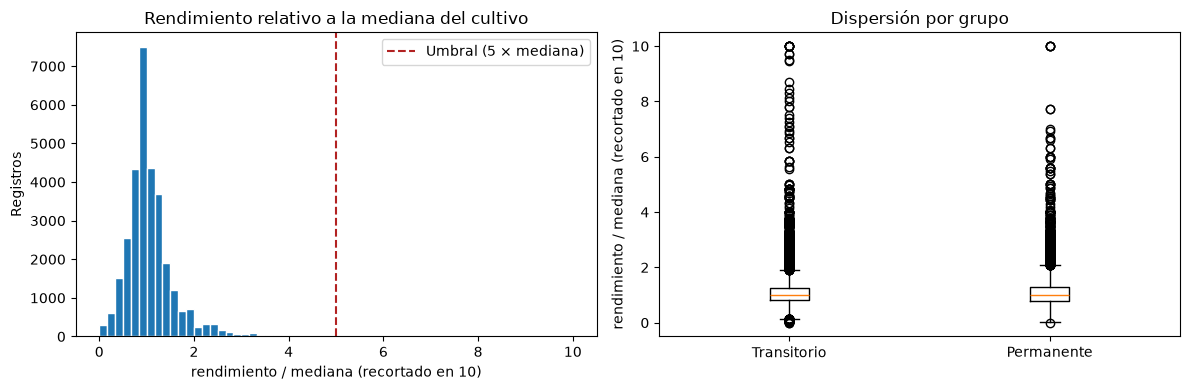

In [177]:
pos = rendimiento[rendimiento["rendimiento_t_ha"] > 0]
q = pos.groupby(["grupo", "cultivo"])["rendimiento_t_ha"].quantile([0.25, 0.75]).unstack()
q.columns = ["q1", "q3"]
q["limite_iqr"] = q["q3"] + 1.5 * (q["q3"] - q["q1"])
tmp = rendimiento.join(q["limite_iqr"], on=["grupo", "cultivo"])
display(pd.Series({"marcados por 5 × mediana (la que usamos)": int(rendimiento["atipico"].sum()),
                   "marcados por IQR": int((tmp["rendimiento_t_ha"] > tmp["limite_iqr"]).sum()),
                   "registros con rendimiento > 0": len(pos)}, name="registros"))

pos_idx = pos.assign(relativo=pos["rendimiento_t_ha"] / pos["mediana_cultivo"]).dropna(subset=["relativo"])
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
ejes[0].hist(pos_idx["relativo"].clip(upper=10), bins=60, edgecolor="white")
ejes[0].axvline(FACTOR_ATIPICO, color="firebrick", linestyle="--", label=f"Umbral ({FACTOR_ATIPICO} × mediana)")
ejes[0].set(title="Rendimiento relativo a la mediana del cultivo", xlabel="rendimiento / mediana (recortado en 10)", ylabel="Registros")
ejes[0].legend()
por_grupo = [pos_idx.loc[pos_idx["grupo"] == g, "relativo"].clip(upper=10) for g in ["Transitorio", "Permanente"]]
ejes[1].boxplot(por_grupo)
ejes[1].set_xticklabels(["Transitorio", "Permanente"])
ejes[1].set(title="Dispersión por grupo", ylabel="rendimiento / mediana (recortado en 10)")
plt.tight_layout()
plt.show()

> **Limitación:** el café aparece con rendimientos de 5 t/ha frente a una mediana cercana a 0,9. Puede ser una diferencia de unidad (cereza frente a pergamino seco), pero con estos datos no se puede confirmar; quedan como atípicos excluidos.

---
# 5. Producción de raíces, hortalizas y frutales

Estos tres conjuntos aportan **producción en toneladas**. Se apilan, se agrupan por la llave (si una llave se repite se promedia y se marca si los valores **discrepan**) y después se unirán a la tabla de rendimiento en un solo archivo.

In [178]:
COLS_PROD = BASE_COLS + ["subregion", "produccion_toneladas"]
produccion = pd.concat([datos[n][COLS_PROD].assign(fuente=n) for n in FUENTES_PROD], ignore_index=True)

prod_u = produccion.groupby(LLAVE, as_index=False).agg(
    municipio=("municipio", "first"), subregion=("subregion", "first"), cultivo=("cultivo", "first"),
    produccion_complementaria_t=("produccion_toneladas", "mean"),
    n_valores_distintos=("produccion_toneladas", "nunique"),
    fuentes_produccion=("fuente", lambda s: ",".join(sorted(set(s)))))
prod_u["produccion_conflicto"] = prod_u["n_valores_distintos"] > 1
prod_u = prod_u.drop(columns="n_valores_distintos")

registrar("Producción: apilar y agrupar por llave", len(produccion), len(prod_u), "concat de raíces, hortalizas y frutales + groupby (promedio)")
anotar("T3 Estructurar", "Producción: llaves con valores en conflicto marcadas", "Registros marcados", prod_u["produccion_conflicto"].sum())
print(produccion.shape, "->", prod_u.shape)
produccion.groupby("fuente").agg(filas=("anio", "size"), anios=("anio", "nunique"), municipios=("id_municipio", "nunique"),
                                 cultivos=("id_cultivo", "nunique"), toneladas=("produccion_toneladas", "sum"))

(21208, 9) -> (20801, 10)


,filas,anios,municipios,cultivos,toneladas
fuente,,,,,
frutales,9953,23,42,38,1.637312e+07
hortalizas,9517,23,41,25,2.157268e+06
raices,1738,23,42,10,6.202271e+05


---
# 6. Unificar todo en una sola tabla

Se une la tabla de rendimiento limpia con la producción complementaria por la llave (`anio + id_municipio + id_cultivo + ciclo`), con `how="outer"`: se conserva todo lo que tiene rendimiento **y** los registros que solo existen en las tablas de producción (marcados con `tiene_rendimiento = False` y `grupo = "Solo producción"`). `validate="one_to_one"` garantiza que no se dupliquen filas.

No se mezclan mediciones: `produccion_toneladas` (consolidado) y `produccion_complementaria_t` (otras fuentes) quedan en columnas separadas.

In [179]:
unif = rendimiento_limpio.merge(prod_u, on=LLAVE, how="outer", suffixes=("", "_p"), indicator=True, validate="one_to_one")
cruce_unif = unif["_merge"].value_counts()

for c in ["municipio", "subregion", "cultivo"]:
    unif[c] = unif[c].fillna(unif[c + "_p"])
unif = unif.drop(columns=[c + "_p" for c in ["municipio", "subregion", "cultivo"]])

unif["tiene_rendimiento"] = unif["rendimiento_t_ha"].notna()
unif["grupo"] = unif["grupo"].fillna("Solo producción")
unif["tipo_cultivo"] = unif["tipo_cultivo"].fillna(unif["fuentes_produccion"])
for c in ["es_cero", "alerta_consistencia", "produccion_conflicto"]:
    unif[c] = unif[c].fillna(False).astype(bool)
unif = unif.drop(columns=["_merge", "sin_siembra", "atipico"])

orden = ["anio", "id_municipio", "municipio", "subregion", "grupo", "tipo_cultivo", "id_cultivo", "cultivo", "ciclo",
         "rendimiento_t_ha", "hectareas_sembradas", "hectareas_cosechadas", "produccion_toneladas",
         "produccion_complementaria_t", "fuentes_produccion", "produccion_conflicto",
         "mediana_cultivo", "tiene_rendimiento", "es_cero", "alerta_consistencia"]
assert set(orden) == set(unif.columns), {"sin ubicar": set(unif.columns) - set(orden), "inexistentes": set(orden) - set(unif.columns)}
cultivos_limpio = unif[orden].sort_values(["grupo", "subregion", "municipio", "cultivo", "anio", "ciclo"]).reset_index(drop=True)

registrar("Tabla unificada final", len(rendimiento_limpio) + len(prod_u), len(cultivos_limpio), "merge outer de rendimiento limpio + producción complementaria")

# Tabla 1: resultado del cruce
etiquetas = {"both": "Con rendimiento y producción complementaria",
             "left_only": "Solo rendimiento",
             "right_only": "Solo producción"}
tabla_cruce = pd.DataFrame({
    "Tipo de registro": [etiquetas[k] for k in etiquetas],
    "Registros": [int(cruce_unif.get(k, 0)) for k in etiquetas],
})
tabla_cruce["% del total"] = tabla_cruce["Registros"] / tabla_cruce["Registros"].sum() * 100
tabla_cruce.loc[len(tabla_cruce)] = ["TOTAL", tabla_cruce["Registros"].sum(), 100.0]
display(tabla_cruce.style.format({"Registros": "{:,.0f}", "% del total": "{:.1f}%"}).hide(axis="index")
        .set_caption("Cruce de rendimiento limpio con producción complementaria"))

# Tabla 2: dimensiones de la tabla final
display(pd.DataFrame({"Filas": [f"{cultivos_limpio.shape[0]:,}"],
                      "Columnas": [cultivos_limpio.shape[1]]}).style.hide(axis="index")
        .set_caption("Dimensiones de cultivos_limpio"))

# Vista previa
cultivos_limpio.head()

Tipo de registro,Registros,% del total
Con rendimiento y producción complementaria,"20,577",65.2%
Solo rendimiento,"10,753",34.1%
Solo producción,224,0.7%
TOTAL,"31,554",100.0%


Filas,Columnas
"31,554",20


,anio,id_municipio,municipio,subregion,grupo,tipo_cultivo,id_cultivo,cultivo,ciclo,rendimiento_t_ha,hectareas_sembradas,hectareas_cosechadas,produccion_toneladas,produccion_complementaria_t,fuentes_produccion,produccion_conflicto,mediana_cultivo,tiene_rendimiento,es_cero,alerta_consistencia
0,2000,76036,Andalucia,Centro,Permanente,frutales,2040202,Aguacate,Anual,10.0,4.0,4.0,40.0,40.0,frutales,False,9.22,True,False,False
1,2001,76036,Andalucia,Centro,Permanente,frutales,2040202,Aguacate,Anual,10.0,3.9,3.9,39.0,39.0,frutales,False,9.22,True,False,False
2,2002,76036,Andalucia,Centro,Permanente,frutales,2040202,Aguacate,Anual,10.0,6.4,3.9,39.0,39.0,frutales,False,9.22,True,False,False
3,2003,76036,Andalucia,Centro,Permanente,frutales,2040202,Aguacate,Anual,10.0,9.0,6.5,65.0,65.0,frutales,False,9.22,True,False,False
4,2004,76036,Andalucia,Centro,Permanente,frutales,2040202,Aguacate,Anual,10.0,9.0,6.5,65.0,65.0,frutales,False,9.22,True,False,False


### Faltantes que NO se completan
- `hectareas_cosechadas` y `produccion_toneladas` en **transitorios**: esos conjuntos no traen la variable (faltante **estructural**); inventarla mezclaría un valor calculado con uno medido.
- `rendimiento_t_ha` en registros `Solo producción`: no hay medición.
- `mediana_cultivo` en cultivos sin ningún rendimiento positivo: sin referencia no se calcula.

> Forzar "cero nulos" aquí empeoraría los datos.

In [180]:
faltantes = cultivos_limpio.isna().sum()
display(faltantes[faltantes > 0].to_frame("nulos").assign(pct=lambda t: (t["nulos"] / len(cultivos_limpio) * 100).round(2)))
pd.crosstab(cultivos_limpio["grupo"], cultivos_limpio["hectareas_cosechadas"].isna(), colnames=["hectareas_cosechadas faltante"])

,nulos,pct
rendimiento_t_ha,224,0.71
hectareas_sembradas,224,0.71
hectareas_cosechadas,16316,51.71
produccion_toneladas,16316,51.71
produccion_complementaria_t,10753,34.08
fuentes_produccion,10753,34.08
mediana_cultivo,230,0.73


hectareas_cosechadas faltante,False,True
grupo,,
Permanente,15238,0
Solo producción,0,224
Transitorio,0,16092


---
# 7. CARGAR: guardar un solo CSV

Se guarda **un único archivo**: `data/procesados/cultivos_limpio.csv` (`utf-8-sig`, para que Excel muestre bien tildes y la `Ñ`). Al volver a leerlo hay que usar `dtype={"id_municipio": str, "id_cultivo": str}` para no perder los ceros de los códigos.

In [181]:
cultivos_limpio.to_csv(ARCHIVO_SALIDA, index=False, encoding="utf-8-sig")
print(f"Guardado: {ARCHIVO_SALIDA} ({os.path.getsize(ARCHIVO_SALIDA) / 1e6:.2f} MB) · {len(cultivos_limpio):,} filas · {cultivos_limpio.shape[1]} columnas")

Guardado: data/procesados/cultivos_limpio.csv (4.20 MB) · 31,554 filas · 20 columnas


---
# 8. Validación final
Se valida el **archivo guardado** (no las variables en memoria), así se comprueba que el guardado no alteró nada. Cada `assert` detiene el cuaderno si falla; si la celda termina sin error, todas las pruebas pasaron.

In [182]:
final = pd.read_csv(ARCHIVO_SALIDA, dtype={"id_municipio": str, "id_cultivo": str})

assert final.shape == cultivos_limpio.shape, (final.shape, cultivos_limpio.shape)
assert not final.duplicated(LLAVE).any(), "Hay llaves repetidas"
assert final["id_municipio"].str.fullmatch(r"76\d{3}").all(), "DIVIPOLA inválido"
assert final["anio"].between(ANIO_MIN, ANIO_MAX).all()
for c in ["rendimiento_t_ha", "hectareas_sembradas", "hectareas_cosechadas", "produccion_toneladas", "produccion_complementaria_t"]:
    assert (final[c].dropna() >= 0).all(), f"{c} con negativos"
assert final["subregion"].notna().all() and set(final["subregion"]) <= SUBREGIONES
assert set(final["grupo"]) <= {"Transitorio", "Permanente", "Solo producción"}
assert (final["tiene_rendimiento"] == final["rendimiento_t_ha"].notna()).all()
assert (final["es_cero"] == (final["rendimiento_t_ha"] == 0)).all()
assert final.loc[final["grupo"] == "Transitorio", "hectareas_cosechadas"].isna().all()   # faltante estructural
assert (final["mediana_cultivo"].dropna() > 0).all()
assert final.loc[final["grupo"] == "Solo producción", "produccion_complementaria_t"].notna().all()

for c in ["municipio", "cultivo", "ciclo", "subregion", "tipo_cultivo", "grupo"]:
    s = final[c].astype(str)
    assert (s == s.str.strip()).all(), c
    assert not s.str.contains(r"\s{2,}").any(), c
    assert not s.str.upper().isin(MARCADORES_FALTANTE).any(), c
assert final.groupby("id_municipio")["municipio"].nunique().max() == 1
assert final.groupby("id_cultivo")["cultivo"].nunique().max() == 1
if CORREGIR_ID_CULTIVO:
    assert (final["id_cultivo"].str.len().ge(LARGO_ID_CULTIVO) | final["id_cultivo"].isin(NO_CORREGIDOS)).all(), "Quedan códigos de cultivo truncados"

print("Validación final: todas las pruebas pasaron")
final.groupby("grupo").agg(filas=("anio", "size"), municipios=("id_municipio", "nunique"), cultivos=("id_cultivo", "nunique"),
                           anio_min=("anio", "min"), anio_max=("anio", "max"))

Validación final: todas las pruebas pasaron


,filas,municipios,cultivos,anio_min,anio_max
grupo,,,,,
Permanente,15238,42,61,2000,2023
Solo producción,224,23,29,2000,2020
Transitorio,16092,42,55,2000,2022


---
# 9. Reporte de calidad de datos
## 9.1 Filas antes y después de cada etapa

In [183]:
lecturas = pd.DataFrame([{"etapa": f"{n}: lectura del CSV", "filas_antes": len(crudos[n]), "filas_despues": len(crudos[n]),
                          "decision": "Sin eliminación de filas"} for n in NOMBRES_AGRO])
reporte_filas = pd.concat([lecturas, pd.DataFrame(LOG_ETAPAS)], ignore_index=True)
reporte_filas["filas_eliminadas"] = reporte_filas["filas_antes"] - reporte_filas["filas_despues"]
reporte_filas

,etapa,filas_antes,filas_despues,decision,filas_eliminadas
0,raices: lectura del CSV,1773,1773,Sin eliminación de filas,0
1,rend_trans: lectura del CSV,16748,16748,Sin eliminación de filas,0
2,sup_trans: lectura del CSV,16748,16748,Sin eliminación de filas,0
3,sup_perm: lectura del CSV,14590,14590,Sin eliminación de filas,0
4,consol_perm: lectura del CSV,15282,15282,Sin eliminación de filas,0
5,hortalizas: lectura del CSV,9536,9536,Sin eliminación de filas,0
6,frutales: lectura del CSV,9992,9992,Sin eliminación de filas,0
7,raices: copias exactas,1773,1738,drop_duplicates() sobre todas las columnas,35
8,rend_trans: copias exactas,16748,16441,drop_duplicates() sobre todas las columnas,307
9,sup_trans: copias exactas,16748,16325,drop_duplicates() sobre todas las columnas,423


## 9.2 Porcentaje de nulos por columna (antes y después)
**Antes:** sobre los CSV originales (celdas vacías y marcadores; una columna inexistente cuenta como 100 %). **Después:** sobre el archivo final.

In [184]:
def pct_antes(nombre, col):
    d = crudos_arm[nombre]
    if col not in d.columns:
        return 100.0
    s = d[col]
    return round(float((s.isna() | s.str.strip().str.upper().isin(MARCADORES_FALTANTE)).mean() * 100), 2)

def pct_despues(df, col):
    return round(float(df[col].isna().mean() * 100), 2) if len(df) else np.nan

t_f = final[final["grupo"] == "Transitorio"]
p_f = final[final["grupo"] == "Permanente"]
filas_nulos = [
    ("rendimiento_t_ha", "rend_trans → Transitorio", pct_antes("rend_trans", "rendimiento_t_ha"), pct_despues(t_f, "rendimiento_t_ha"), "Sin acción"),
    ("rendimiento_t_ha", "consol_perm → Permanente", pct_antes("consol_perm", "rendimiento_t_ha"), pct_despues(p_f, "rendimiento_t_ha"), "Sin acción"),
    ("hectareas_sembradas", "sup_trans → Transitorio", pct_antes("sup_trans", "hectareas_sembradas"), pct_despues(t_f, "hectareas_sembradas"), "Sin imputar"),
    ("hectareas_sembradas", "consol_perm → Permanente", pct_antes("consol_perm", "hectareas_sembradas"), pct_despues(p_f, "hectareas_sembradas"), "Sin imputar"),
    ("hectareas_cosechadas", "consol_perm → Permanente", pct_antes("consol_perm", "hectareas_cosechadas"), pct_despues(p_f, "hectareas_cosechadas"), "Sin imputar"),
    ("hectareas_cosechadas", "Transitorio (no existe en el origen)", 100.0, pct_despues(t_f, "hectareas_cosechadas"), "Faltante estructural: no se completa"),
    ("subregion", "consol_perm → Permanente (no existe en el origen)", pct_antes("consol_perm", "subregion"), pct_despues(p_f, "subregion"), "Completada con el catálogo municipio → subregión"),
    ("subregion", "rend_trans → Transitorio", pct_antes("rend_trans", "subregion"), pct_despues(t_f, "subregion"), "Sin acción"),
]
display(pd.DataFrame(filas_nulos, columns=["columna", "conjunto", "pct_nulos_antes", "pct_nulos_despues", "decision"]))
print("Nulos por columna en el archivo final:")
final.isna().mean().mul(100).round(2).rename("pct_nulos").to_frame()

,columna,conjunto,pct_nulos_antes,pct_nulos_despues,decision
0,rendimiento_t_ha,rend_trans → Transitorio,0.0,0.0,Sin acción
1,rendimiento_t_ha,consol_perm → Permanente,0.0,0.0,Sin acción
2,hectareas_sembradas,sup_trans → Transitorio,0.0,0.0,Sin imputar
3,hectareas_sembradas,consol_perm → Permanente,0.0,0.0,Sin imputar
4,hectareas_cosechadas,consol_perm → Permanente,0.0,0.0,Sin imputar
5,hectareas_cosechadas,Transitorio (no existe en el origen),100.0,100.0,Faltante estructural: no se completa
6,subregion,consol_perm → Permanente (no existe en el origen),100.0,0.0,Completada con el catálogo municipio → subregión
7,subregion,rend_trans → Transitorio,0.0,0.0,Sin acción


Nulos por columna en el archivo final:


,pct_nulos
anio,0.00
id_municipio,0.00
municipio,0.00
subregion,0.00
grupo,0.00
tipo_cultivo,0.00
id_cultivo,0.00
cultivo,0.00
ciclo,0.00
rendimiento_t_ha,0.71


## 9.3 Resumen y registro de cambios
Las cantidades se cuentan **por celda o por registro**. Los *registros marcados* no se eliminan: llevan una bandera (`es_cero`, `alerta_consistencia`, `produccion_conflicto`) para que el análisis decida.

In [185]:
registro = pd.DataFrame(CAMBIOS)
resumen = (registro.groupby("tipo", sort=False)["cantidad"].sum().to_frame("cantidad"))
display(pd.DataFrame({"antes": [sum(len(crudos[n]) for n in NOMBRES_AGRO)], "después": [len(final)]},
                     index=["filas leídas (7 CSV) → filas en cultivos_limpio.csv"]))
display(resumen)
registro

,antes,después
filas leídas (7 CSV) → filas en cultivos_limpio.csv,84669,31554


,cantidad
tipo,
Columnas renombradas,9
Filas eliminadas,1235
Columnas eliminadas,0
Valores corregidos,69106
Columnas convertidas,18
Registros marcados,433


,etapa,operacion,tipo,cantidad,detalle
0,Preparación,raices: columnas armonizadas,Columnas renombradas,1,ano → anio
1,Preparación,rend_trans: columnas armonizadas,Columnas renombradas,2,"ano → anio, rendimiento_toneladas_hectareas → rendimiento_t_ha"
2,Preparación,sup_trans: columnas armonizadas,Columnas renombradas,1,ano → anio
3,Preparación,sup_perm: columnas armonizadas,Columnas renombradas,1,ano → anio
4,Preparación,consol_perm: columnas armonizadas,Columnas renombradas,2,"ano → anio, rendimiento_toneladas_hectareas → rendimiento_t_ha"
5,Preparación,hortalizas: columnas armonizadas,Columnas renombradas,1,ano → anio
6,Preparación,frutales: columnas armonizadas,Columnas renombradas,1,ano → anio
7,T1 Eliminar,raices: copias exactas,Filas eliminadas,35,
8,T1 Eliminar,rend_trans: copias exactas,Filas eliminadas,307,
9,T1 Eliminar,sup_trans: copias exactas,Filas eliminadas,423,


---
## Decisiones y justificación

| Hallazgo | Decisión | Justificación |
|---|---|---|
| Números escritos con formatos distintos (`1,6`, `1.264`, `4,324.8`) | `a_numero` con el formato de cada archivo (`FORMATO_NUM`) | `to_numeric` directo daría `NaN` o un valor equivocado |
| `consol_perm` con ids y años con coma (`76,001`) | `limpiar_codigo` + `zfill(5)` | DIVIPOLA debe ser texto de 5 dígitos para cruzar |
| `id_cultivo` truncado (4 a 6 dígitos) | Relleno con ceros finales en **todos** los conjuntos, sin chocar con otro cultivo | El mismo cultivo no puede tener dos códigos |
| Copias exactas | `drop_duplicates()` | Contarían dos veces las hectáreas |
| Llave repetida con valores distintos | Promedio por llave (transitorios y producción); marca `produccion_conflicto` | Evita inflar sumas; no se sabe cuál valor es el correcto |
| `consol_perm` sin subregión | Catálogo municipio → subregión | Los demás conjuntos la traen y cada municipio tiene una sola |
| Rendimiento 0 con 0 ha | Se excluye | Sin siembra no hay rendimiento |
| Rendimiento 0 con siembra | Se conserva con `es_cero` | Puede ser pérdida de cosecha |
| Rendimiento > 5 × mediana del cultivo | Se excluye | Probable error de digitación; regla relativa por cultivo |
| Producción ≠ rendimiento × cosechadas, o rendimiento sin hectáreas | `alerta_consistencia` (no se elimina) | El rendimiento se publica redondeado |
| `hectareas_cosechadas` en transitorios | Se deja vacío | Faltante estructural |
| Producción de raíces, hortalizas y frutales | Columna separada `produccion_complementaria_t` | No mezclar fuentes distintas en una misma medición |
| Registros solo con producción | Se conservan (`tiene_rendimiento = False`) | Información útil para la Parte 2; filtrables |

## Limitaciones conocidas
- **Periodos distintos:** transitorios hasta 2022, permanentes hasta 2023; comparar grupos solo en el periodo común.
- **`tipo_cultivo` en permanentes:** el consolidado mezcla frutales, hortalizas, raíces y flores con ciclo anual.
- **Códigos de cultivo corregidos por inferencia:** no se pueden verificar contra otra fuente.
- **Café con rendimientos altos:** posible diferencia de unidad, no confirmable.
- **Datos municipales:** describen municipios, no productores (falacia ecológica).

## Conclusiones
1. Explorar antes de transformar orienta cada decisión.
2. Leer todo como texto evita perder ceros de códigos y malinterpretar separadores.
3. Los problemas invisibles (separadores dentro de códigos, ceros finales perdidos) son los más peligrosos.
4. No todo faltante se imputa: primero se averigua por qué falta.
5. Los atípicos estadísticos no se eliminan a ciegas: el dominio decide.
6. Cruzar fuentes es una prueba de calidad (`sup_perm` vs `consol_perm`).
7. Validar sobre el archivo guardado con `assert` hace la calidad comprobable.

**Salida de la Parte 1:** `data/procesados/cultivos_limpio.csv`, lista para cruzarse con la temperatura en la Parte 2 por `id_municipio`/`municipio` y `anio`.